## Adjusted Associations between Loneliness and Immune Biomarkers, Psych Diagnoses, and Immune Conditions

In [129]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(broom)
})

# ------------------------------------------------------------------------------
# CONFIG -----------------------------------------------------------------------
# ------------------------------------------------------------------------------

dataset <- Sys.getenv("WORKSPACE_CDR")
project <- Sys.getenv("GOOGLE_PROJECT")
#copy rds
system(
  'gcloud storage cp "$WORKSPACE_BUCKET/workspace/cleaned_data/dat_with_immune_and_psych_conditions.rds" .'
)
    


### Config

In [130]:
DATA_PATH <- "dat_with_immune_and_psych_conditions.rds"
OUT_DIR <- "$WORKSPACE_BUCKET/workspace/conference_results/results_04_mutual_adjustment"
dir.create(OUT_DIR, showWarnings = FALSE, recursive = TRUE)

LONELINESS_VAR <- "total_score"   # UCLA sum score, 0-24, pre-scored

BIOMARKERS <- c("crp", "albumin", "basophils", "eosinophils", "leukocytes",
                "monocytes", "neutrophils", "platelets", "triglycerides")

PSYCH_DEF <- "2plus"   # "1plus" or "2plus" - means classified at leasst 2 separate occasions to avoid misclassification
PSYCH_STEMS <- c("anxiety", "depression", "ptsd", "adhd", "bipolar",
                 "eating_disorder", "ocd", "schizophrenia", "asd",
                 "personality_disorder")
IMMUNE_CONDITIONS <- c("asthma", "allergic_rhinitis", "rheumatoid_arthritis",
                       "hypothyroidism", "ulcerative_colitis", "type2_diabetes",
                       "crohns_disease", "atopic_dermatitis")
PSYCH_CONDITIONS <- paste0(PSYCH_STEMS, "_psych_", PSYCH_DEF)

# Covariates: income, sex, race + age + BMI (user-confirmed full set).
COVARIATES <- c("income_ordinal", "sex_at_birth", "race_group",
                "age_at_ucla", "bmi")

# Sensitivity: drop BMI (may be on the causal pathway).
RUN_NO_BMI_SENSITIVITY <- TRUE

FDR_ALPHA <- 0.05

# ------------------------------------------------------------------------------
# LOAD + PREP ------------------------------------------------------------------
# ------------------------------------------------------------------------------

cohort <- if (grepl("\\.rds$", DATA_PATH, ignore.case = TRUE)) {
  readRDS(DATA_PATH)
} else {
  read.csv(DATA_PATH)
}

# male and female sex assigned at birth only
cohort <- cohort %>%
  filter(tolower(sex_at_birth) %in% c("male", "female"))

needed <- c(LONELINESS_VAR, BIOMARKERS, PSYCH_CONDITIONS, IMMUNE_CONDITIONS,
            COVARIATES)
missing <- setdiff(needed, names(cohort))
if (length(missing) > 0) {
  stop("Columns not found in extract: ", paste(missing, collapse = ", "))
}

cohort <- cohort %>%
  mutate(
    loneliness_c = .data[[LONELINESS_VAR]] -
      mean(.data[[LONELINESS_VAR]], na.rm = TRUE),
    income_c = income_ordinal - mean(income_ordinal, na.rm = TRUE)
  )

# NOTE: assumes the RDS is analysis-ready 

f_cov <- paste(COVARIATES, collapse = " + ")
f_cov_c <- paste(c("income_c", COVARIATES[COVARIATES != "income_ordinal"]),
                 collapse = " + ")

# VIF from the model matrix (no car dependency): 1 / (1 - R2_j) via auxiliary
# regressions on the design matrix columns.
vif_manual <- function(fit) {
  X <- model.matrix(fit)[, -1, drop = FALSE]
  X <- X[, apply(X, 2, var, na.rm = TRUE) > 0, drop = FALSE]  # drop constants
  sapply(colnames(X), function(j) {
    r2 <- summary(lm(X[, j] ~ X[, setdiff(colnames(X), j)]))$r.squared
    1 / (1 - r2)
  })
}

In [3]:
head(cohort)

,person_id,survey_date,total_score,albumin,basophils,crp,eosinophils,leukocytes,monocytes,neutrophils,⋯,anxiety_psych_2plus,personality_disorder_psych_2plus,n_selected_psych_1plus,n_selected_psych_2plus,any_selected_psych_1plus,any_selected_psych_2plus,no_selected_psych_2plus,no_selected_psych_or_immune,loneliness_c,income_c
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<dbl>,<dbl>
1,200001000003,2022-03-07,9,NA,0.1,NA,0.2,5.5,0.5,3.3,⋯,0,0,1,0,1,0,1,0,1.427204,1.6234263
2,200001000024,2021-11-12,3,NA,0.0,NA,0.1,10.1,0.7,7.2,⋯,1,0,1,1,1,1,0,0,-4.572796,0.6234263
3,200001000083,2021-03-25,21,42,NA,1.1,NA,NA,NA,NA,⋯,0,0,2,0,1,0,1,0,13.427204,-3.3765737
4,200001000096,2021-04-19,9,NA,NA,NA,NA,NA,NA,NA,⋯,0,0,0,0,0,0,1,0,1.427204,-2.3765737
5,200001000120,2022-07-17,12,NA,NA,NA,NA,NA,NA,NA,⋯,1,0,1,1,1,1,0,0,4.427204,-4.3765737
6,200001000144,2023-06-22,9,41,0.1,NA,0.3,9.0,0.7,6.2,⋯,0,0,0,0,0,0,1,0,1.427204,0.6234263


### Loneliness and Psychiatric Disorders
- OR adjusting for age, sex, bmi, income and race for each psychiatric disorder
- keep FDR-significant and include all in models with loneliness as the outcome

In [8]:
library(dplyr)
library(ggplot2)

psych_2plus_cols <- c(
  "anxiety_psych_2plus",
  "adhd_psych_2plus",
  "asd_psych_2plus",
  "bipolar_psych_2plus",
  "eating_disorder_psych_2plus",
  "depression_psych_2plus",
  "ocd_psych_2plus",
  "personality_disorder_psych_2plus",
  "ptsd_psych_2plus",
  "schizophrenia_psych_2plus"
)

psych_logistic_results <- data.frame()

for (dx in psych_2plus_cols) {

  f <- as.formula(
    paste0(
      dx,
      " ~ total_score + age_at_ucla + sex_at_birth + ",
      "race + income_c + bmi"
    )
  )

  model <- glm(
    f,
    data = cohort,
    family = binomial(link = "logit"),
    na.action = na.omit
  )

  s <- summary(model)

  beta <- s$coefficients["total_score", "Estimate"]
  se   <- s$coefficients["total_score", "Std. Error"]
  p    <- s$coefficients["total_score", "Pr(>|z|)"]

  # Model fit indices
  aic <- AIC(model)

  null_dev <- model$null.deviance
  resid_dev <- model$deviance

  # Likelihood-ratio test comparing full model to intercept-only model
  lr_stat <- null_dev - resid_dev
  lr_df <- model$df.null - model$df.residual
  lr_p <- pchisq(
    lr_stat,
    df = lr_df,
    lower.tail = FALSE
 )

  # McFadden pseudo-R2
  mcfadden_r2 <- 1 - (resid_dev / null_dev)

  # Tjur R2
  pred_prob <- fitted(model)

  tjur_r2 <-
    mean(pred_prob[model$y == 1], na.rm = TRUE) -
    mean(pred_prob[model$y == 0], na.rm = TRUE)

  psych_logistic_results <- rbind(
  psych_logistic_results,
  data.frame(
    diagnosis = dx,
    N = nobs(model),
    N_cases = sum(model$y == 1),

    beta_logodds = beta,
    OR = exp(beta),
    CI_lower = exp(beta - 1.96 * se),
    CI_upper = exp(beta + 1.96 * se),
    p_value = p,

    AIC = aic,
    null_deviance = null_dev,
    residual_deviance = resid_dev,

    LR_chisq = lr_stat,
    LR_df = lr_df,
    LR_p = lr_p,

    McFadden_R2 = mcfadden_r2,
    Tjur_R2 = tjur_r2
    )
  )
}

In [9]:
# FDR
psych_logistic_results <- psych_logistic_results %>%
  mutate(
    FDR = p.adjust(p_value, method = "BH"),

    diagnosis_label = recode(
      diagnosis,
      anxiety_psych_2plus = "Anxiety",
      adhd_psych_2plus = "ADHD",
      asd_psych_2plus = "Autism spectrum disorder",
      bipolar_psych_2plus = "Bipolar disorder",
      eating_disorder_psych_2plus = "Eating disorder",
      depression_psych_2plus = "Depression",
      ocd_psych_2plus = "OCD",
      personality_disorder_psych_2plus = "Personality disorder",
      ptsd_psych_2plus = "PTSD",
      schizophrenia_psych_2plus = "Schizophrenia"
    ),

    stars = case_when(
      FDR < 0.001 ~ "***",
      FDR < 0.01  ~ "**",
      FDR < 0.05  ~ "*",
      TRUE ~ ""
    ),

    plot_label = ifelse(
      stars == "",
      diagnosis_label,
      paste0(diagnosis_label, " ", stars)
    )
  ) %>%
  arrange(OR)

psych_logistic_results

diagnosis,N,N_cases,beta_logodds,OR,CI_lower,CI_upper,p_value,AIC,null_deviance,residual_deviance,LR_chisq,LR_df,LR_p,McFadden_R2,Tjur_R2,FDR,diagnosis_label,stars,plot_label
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
eating_disorder_psych_2plus,183204,1827,0.05395986,1.055442,1.046278,1.064687,7.588988e-34,19401.445,20473.077,19373.445,1099.6327,13,6.825391e-227,0.05371116,0.007804053,8.432209e-34,Eating disorder,***,Eating disorder ***
anxiety_psych_2plus,183204,41171,0.05541738,1.056982,1.054685,1.059283,0.000000e+00,186869.640,195231.990,186841.640,8390.3498,13,0.000000e+00,0.04297631,0.046243482,0.000000e+00,Anxiety,***,Anxiety ***
adhd_psych_2plus,183204,7040,0.05576048,1.057344,1.052516,1.062195,5.227547e-126,55124.631,59692.549,55096.631,4595.9180,13,0.000000e+00,0.07699316,0.027911930,8.712578e-126,ADHD,***,ADHD ***
schizophrenia_psych_2plus,183204,412,0.06323235,1.065274,1.046823,1.084050,1.308949e-12,5007.537,5847.275,4979.537,867.7378,13,4.216002e-177,0.14840039,0.009270887,1.308949e-12,Schizophrenia,***,Schizophrenia ***
ocd_psych_2plus,183204,974,0.07350603,1.076275,1.063647,1.089053,2.853747e-34,11539.048,12144.380,11511.048,633.3320,13,5.961917e-127,0.05215021,0.004135218,3.567184e-34,OCD,***,OCD ***
depression_psych_2plus,183204,37730,0.07674730,1.079769,1.077336,1.082207,0.000000e+00,175101.556,186331.178,175073.556,11257.6225,13,0.000000e+00,0.06041728,0.062924295,0.000000e+00,Depression,***,Depression ***
bipolar_psych_2plus,183204,4802,0.07878449,1.081971,1.076172,1.087802,1.504307e-181,40175.421,44450.636,40147.421,4303.2157,13,0.000000e+00,0.09680887,0.031240673,3.760768e-181,Bipolar disorder,***,Bipolar disorder ***
ptsd_psych_2plus,183204,7266,0.09125170,1.095545,1.090713,1.100398,0.000000e+00,56622.821,61140.433,56594.821,4545.6119,13,0.000000e+00,0.07434707,0.030469077,0.000000e+00,PTSD,***,PTSD ***
personality_disorder_psych_2plus,183204,1794,0.12150911,1.129200,1.119251,1.139237,1.601929e-159,17792.160,20169.010,17764.160,2404.8503,13,0.000000e+00,0.11923492,0.020403803,3.203859e-159,Personality disorder,***,Personality disorder ***


`height` was translated to `width`.


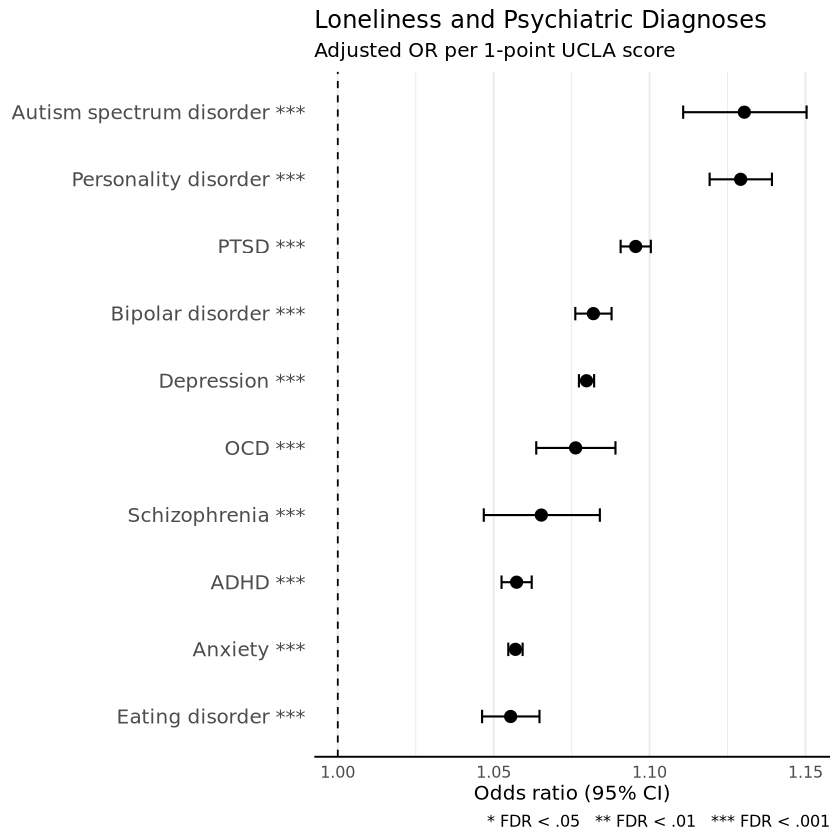

In [63]:
p_psych_or <- ggplot(
  psych_logistic_results,
  aes(
    x = OR,
    y = reorder(plot_label, OR)
  )
) +
  geom_vline(
    xintercept = 1,
    linetype = "dashed",
    linewidth = 0.5
  ) +
  geom_errorbarh(
    aes(
      xmin = CI_lower,
      xmax = CI_upper
    ),
    height = 0.2,
    linewidth = 0.6,
    color = "black"
  ) +
  geom_point(
    size = 3,
    color = "black"
  ) +
  labs(
    title = "Loneliness and Psychiatric Diagnoses",
    subtitle = "Adjusted OR per 1-point UCLA score",
    x = "Odds ratio (95% CI)",
    y = NULL,
    caption = "* FDR < .05   ** FDR < .01   *** FDR < .001"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    panel.grid.major.y = element_blank(),
    axis.line.x = element_line(),
    axis.text.y = element_text(size = 12)
    
  )

p_psych_or

In [64]:
# save fig
library(svglite)
ggsave(
  "p_psych_or.png",
  plot = p_psych_or,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_psych_or.svg",
  plot = p_psych_or,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


### Adjusting for all Psych Conditions


In [32]:
library(dplyr)
cohort <- cohort %>%
  mutate(
      loneliness_z = as.numeric(scale(total_score))
      )


In [38]:
model_psych_joint_z <- lm(
    loneliness_z ~ 
        anxiety_psych_2plus +
        adhd_psych_2plus +
        asd_psych_2plus + 
        bipolar_psych_2plus +
        eating_disorder_psych_2plus +
        depression_psych_2plus +
        ocd_psych_2plus +
        personality_disorder_psych_2plus +
        ptsd_psych_2plus +
        schizophrenia_psych_2plus +
        age_at_ucla + 
        sex_at_birth +
        race +
        income_c +
        bmi,
    data = cohort
    )

summary(model_psych_joint_z)


Call:
lm(formula = loneliness_z ~ anxiety_psych_2plus + adhd_psych_2plus + 
    asd_psych_2plus + bipolar_psych_2plus + eating_disorder_psych_2plus + 
    depression_psych_2plus + ocd_psych_2plus + personality_disorder_psych_2plus + 
    ptsd_psych_2plus + schizophrenia_psych_2plus + age_at_ucla + 
    sex_at_birth + race + income_c + bmi, data = cohort)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.1302 -0.7137 -0.1082  0.6297  3.7260 

Coefficients:
                                   Estimate Std. Error  t value Pr(>|t|)    
(Intercept)                       0.2124141  0.0224238    9.473  < 2e-16 ***
anxiety_psych_2plus               0.0359325  0.0067664    5.310 1.10e-07 ***
adhd_psych_2plus                  0.0427864  0.0118527    3.610 0.000306 ***
asd_psych_2plus                   0.3419121  0.0435751    7.847 4.30e-15 ***
bipolar_psych_2plus               0.1756990  0.0144749   12.138  < 2e-16 ***
eating_disorder_psych_2plus       0.0175789  0.0221228    0.795 0.42684

- loneliness no longer associated with:
    - eating disorder
    - ocd
    - schizophrenia
 

In [24]:
# plotting forest plot
library(broom)
library(dplyr)
library(ggplot2)

psych_forest <- tidy(
  model_psych_joint_z,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(grepl("_psych_2plus$", term))

In [25]:
psych_forest <- psych_forest %>%
  mutate(
    diagnosis = term %>%
      sub("_psych_2plus$", "", .) %>%
      recode(
        anxiety = "Anxiety",
        depression = "Depression",
        ptsd = "PTSD",
        adhd = "ADHD",
        asd = "Autism spectrum disorder",
        bipolar = "Bipolar disorder",
        eating_disorder = "Eating disorder",
        ocd = "OCD",
        personality_disorder = "Personality disorder",
        schizophrenia = "Schizophrenia"
      )
  )

`height` was translated to `width`.


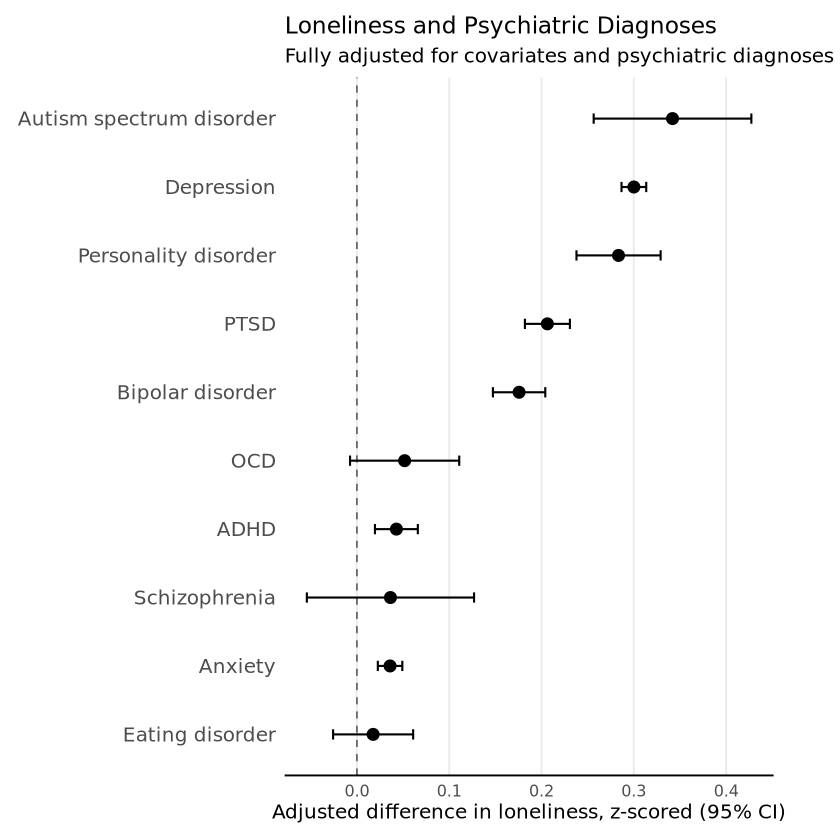

In [56]:
p_psych_joint_z <- ggplot(
  psych_forest,
  aes(
    x = estimate,
    y = reorder(diagnosis, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Loneliness and Psychiatric Diagnoses",
    subtitle = "Fully adjusted for covariates and psychiatric diagnoses",
    x = "Adjusted difference in loneliness, z-scored (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    axis.text.y = element_text(size = 12),
    axis.line.x = element_line(),
    plot.title = element_text(
        hjust = 0,
        size = 14),
    plot.margin = margin(
      t = 10,
      r = 40,
      b = 10,
      l = 10
    )
      )
p_psych_joint_z

`height` was translated to `width`.


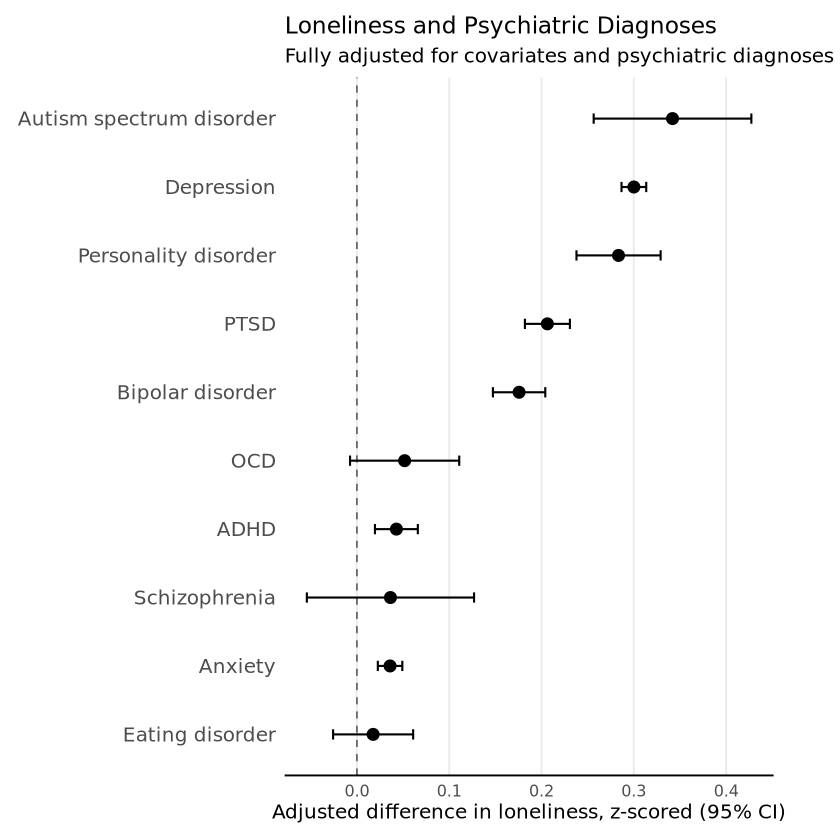

In [57]:
p_psych_joint_z

- adjusting for covariates, and comorbid psychiatric conditions, autism still increases loneliness by 0.35 standard deviations

In [ ]:
### Raw Loneliness Model

In [37]:
model_psych_joint_raw <- lm(
    total_score ~ 
        anxiety_psych_2plus +
        adhd_psych_2plus +
        asd_psych_2plus + 
        bipolar_psych_2plus +
        eating_disorder_psych_2plus +
        depression_psych_2plus +
        ocd_psych_2plus +
        personality_disorder_psych_2plus +
        ptsd_psych_2plus +
        schizophrenia_psych_2plus +
        age_at_ucla + 
        sex_at_birth +
        race +
        income_c +
        bmi,
    data = cohort
    )

summary(model_psych_joint_raw)


Call:
lm(formula = total_score ~ anxiety_psych_2plus + adhd_psych_2plus + 
    asd_psych_2plus + bipolar_psych_2plus + eating_disorder_psych_2plus + 
    depression_psych_2plus + ocd_psych_2plus + personality_disorder_psych_2plus + 
    ptsd_psych_2plus + schizophrenia_psych_2plus + age_at_ucla + 
    sex_at_birth + race + income_c + bmi, data = cohort)

Residuals:
     Min       1Q   Median       3Q      Max 
-16.7163  -3.8113  -0.5781   3.3629  19.8981 

Coefficients:
                                   Estimate Std. Error  t value Pr(>|t|)    
(Intercept)                       8.7071581  0.1197505   72.711  < 2e-16 ***
anxiety_psych_2plus               0.1918916  0.0361351    5.310 1.10e-07 ***
adhd_psych_2plus                  0.2284938  0.0632976    3.610 0.000306 ***
asd_psych_2plus                   1.8259246  0.2327054    7.847 4.30e-15 ***
bipolar_psych_2plus               0.9382910  0.0773007   12.138  < 2e-16 ***
eating_disorder_psych_2plus       0.0938773  0.1181433    0.79

In [37]:
psych_forest_raw <- tidy(
  model_psych_joint_raw,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(grepl("_psych_2plus$", term))

psych_forest_raw <- psych_forest_raw %>%
  mutate(
    diagnosis = term %>%
      sub("_psych_2plus$", "", .) %>%
      recode(
        anxiety = "Anxiety",
        depression = "Depression",
        ptsd = "PTSD",
        adhd = "ADHD",
        asd = "Autism spectrum disorder",
        bipolar = "Bipolar disorder",
        eating_disorder = "Eating disorder",
        ocd = "OCD",
        personality_disorder = "Personality disorder",
        schizophrenia = "Schizophrenia"
      )
  )

`height` was translated to `width`.


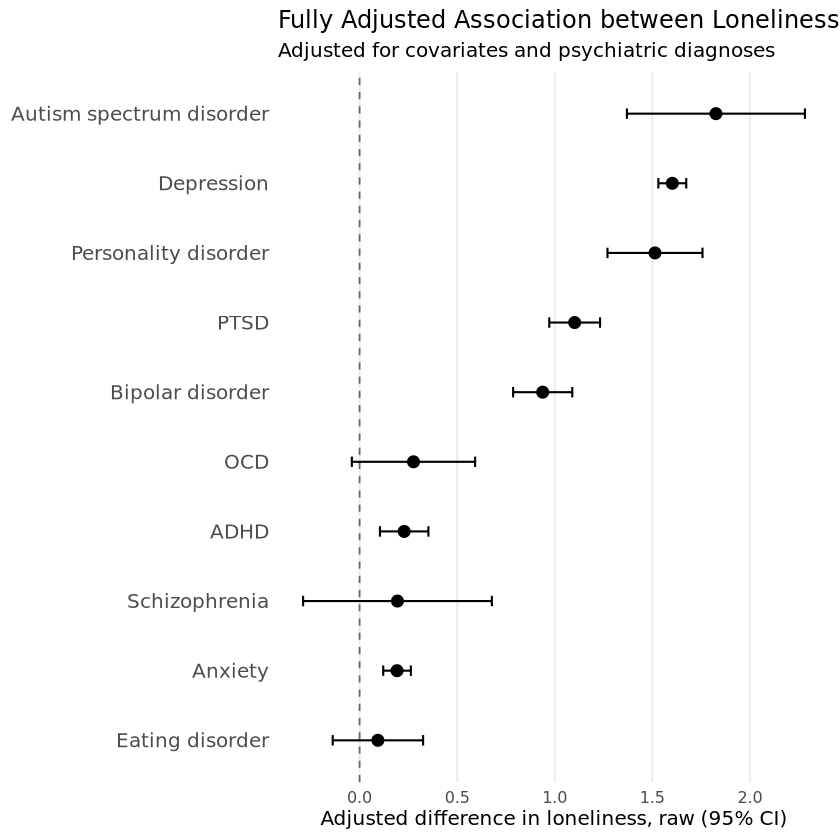

In [40]:
p_psych_joint_raw <- ggplot(
  psych_forest_raw,
  aes(
    x = estimate,
    y = reorder(diagnosis, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Fully Adjusted Association between Loneliness and Psychiatric Diagnoses",
    subtitle = "Adjusted for covariates and psychiatric diagnoses",
    x = "Adjusted difference in loneliness, raw (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    axis.text.y = element_text(size = 12)
  )

p_psych_joint_raw

- autism increases loneliness score by 1.75 points, adjusting for covariates and comorbid diagnoses


In [59]:
install.packages("svglite")

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done



In [60]:
# save fig
library(svglite)
ggsave(
  "p_psych_joint_z.png",
  plot = p_psych_joint_z,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_psych_joint_z.svg",
  plot = p_psych_joint_z,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


In [65]:
# Covariates
cov_forest <- tidy(
  model_psych_joint_z,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(
    term != "(Intercept)",
    !grepl("_psych_2plus$", term)
  )

In [81]:
cov_forest <- cov_forest %>%
  mutate(
    covariate = case_when(
      term == "age_at_ucla" ~ "Age",
      term == "sex_at_birthMale" ~ "Male sex",
      term == "income_c" ~ "Income",
      term == "bmi" ~ "BMI",
      term == "raceAsian" ~ "Race: Asian",
      term == "raceBlack or African American" ~ "Race: Black/African American",
      term == "raceWhite" ~ "Race: White",
      term == "raceMore than one population" ~ "Race: Mixed/Multi",
      term == "raceNone of these" ~ "Race: None of these",
      TRUE ~ term
    )
  )

cov_forest <- cov_forest %>%
  filter(
    term != "(Intercept)",
    !grepl("_psych_2plus$", term),
    !term %in% c(
      "raceNone Indicated",
      "racePMI: Skip",
      "raceI prefer not to answer"
    )
  )

In [74]:
head(cov_forest, 10)

term,estimate,std.error,statistic,p.value,conf.low,conf.high,covariate
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
age_at_ucla,-0.009462163,0.0001389774,-68.084204,0.000000e+00,-0.009734556,-0.009189771,Age
sex_at_birthMale,0.027786758,0.0046285252,6.003372,1.936230e-09,0.018714955,0.036858561,Male sex
raceAsian,0.133815934,0.0227500316,5.882011,4.060121e-09,0.089226397,0.178405471,Race: Asian
raceBlack or African American,-0.051308890,0.0208446560,-2.461489,1.383708e-02,-0.092163935,-0.010453845,Race: Black or African American
raceMore than one population,0.181013049,0.0216644223,8.355314,6.570676e-17,0.138551281,0.223474817,Race: Mixed/Multi
raceNone of these,0.223463482,0.0300205650,7.443680,9.834426e-14,0.164623867,0.282303097,Race: None of these
raceWhite,0.090123166,0.0195715824,4.604797,4.131451e-06,0.051763316,0.128483016,Race: White
income_c,-0.104295531,0.0009877645,-105.587448,0.000000e+00,-0.106231526,-0.102359535,Income
bmi,0.004748985,0.0002988328,15.891781,7.886444e-57,0.004163280,0.005334691,BMI


`height` was translated to `width`.


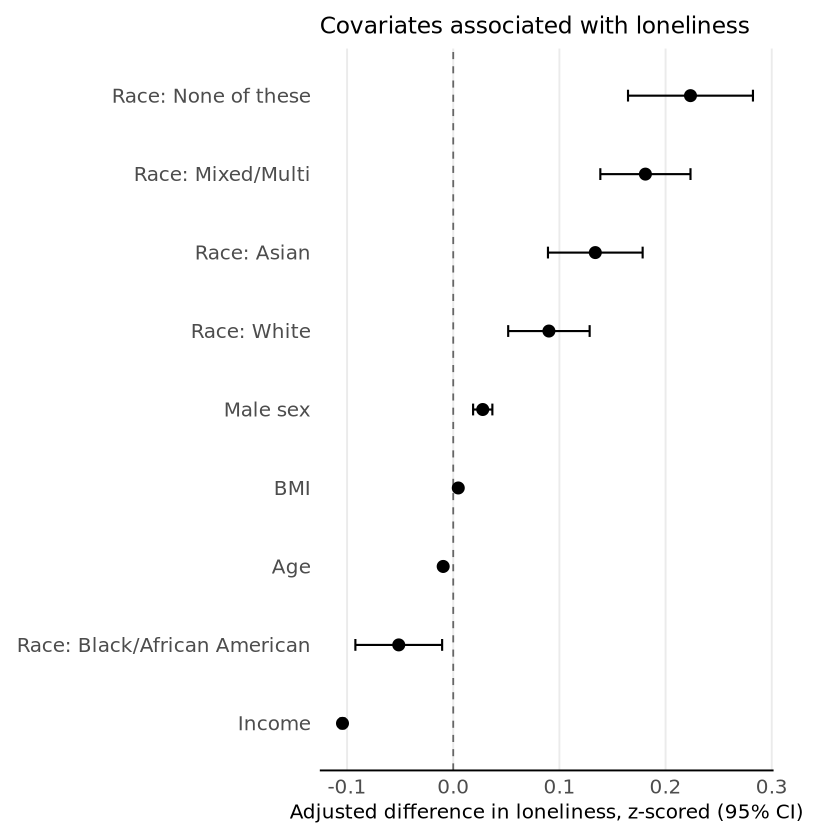

In [84]:
p_cov <- ggplot(
  cov_forest,
  aes(
    x = estimate,
    y = reorder(covariate, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Covariates associated with loneliness",
    x = "Adjusted difference in loneliness, z-scored (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.y = element_text(size = 12),
    axis.text.x = element_text(size = 12),
    plot.title = element_text(size = 14, hjust = 0),
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    axis.line.x = element_line(),
    plot.margin = margin(
      t = 10,
      r = 40,
      b = 10,
      l = 10
    )
      )
    

p_cov

In [85]:
# save fig
library(svglite)
ggsave(
  "p_psych_cov_joint_z.png",
  plot = p_cov,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_psych_cov_joint_z.svg",
  plot = p_cov,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


### Loneliness and Immune Biomarkers (Std)

In [131]:
biomarkers <- c(
  "crp",
  "albumin",
  "basophils",
  "eosinophils",
  "leukocytes",
  "monocytes",
  "neutrophils",
  "platelets",
  "triglycerides"
)

# standardizing
dat <- cohort %>%
  mutate(
    loneliness_z = as.numeric(scale(total_score))
  )

for (bio in biomarkers) {
  dat[[paste0(bio, "_z")]] <- as.numeric(
    scale(dat[[bio]])
  )
}

In [91]:

biomarker_results <- map_dfr(
  biomarkers,
  function(bio) {

    outcome <- paste0(bio, "_z")

    formula <- as.formula(
      paste0(
        outcome,
        " ~ loneliness_z + age_at_ucla + sex_at_birth + ",
        "race + income_c + bmi"
      )
    )

    model <- lm(
      formula,
      data = dat
    )

    tidy(model, conf.int = TRUE) %>%
      filter(term == "loneliness_z") %>%
      mutate(
        biomarker = bio,
        N = nobs(model)
      )
  }
)

In [99]:
biomarker_results <- biomarker_results %>%
  mutate(
    p_fdr = p.adjust(
      p.value,
      method = "BH"
    ),
    fdr_significant = p_fdr < 0.05
  )

In [94]:
names(biomarker_results)

[1] "term"            "estimate"        "std.error"       "statistic"      
 [5] "p.value"         "conf.low"        "conf.high"       "biomarker"      
 [9] "N"               "p_fdr"           "fdr_significant"

In [100]:
biomarker_results %>%
  select(
    biomarker,
    N,
    estimate,
    conf.low,
    conf.high,
    p.value,
    p_fdr,
    fdr_significant
  ) %>%
  arrange(p_fdr)

biomarker,N,estimate,conf.low,conf.high,p.value,p_fdr,fdr_significant
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
platelets,63261,0.0342238009,0.026538797,0.041908805,2.641711e-18,2.377540e-17,TRUE
triglycerides,68132,0.0269682610,0.019407607,0.034528915,2.751154e-12,1.238019e-11,TRUE
leukocytes,59008,0.0124084895,0.004205912,0.020611067,3.027981e-03,9.083942e-03,TRUE
basophils,33722,0.0152841835,0.004399863,0.026168504,5.919980e-03,1.331995e-02,TRUE
eosinophils,36563,-0.0076867842,-0.017337876,0.001964308,1.185088e-01,1.845541e-01,FALSE
neutrophils,33797,0.0085627468,-0.002319987,0.019445481,1.230361e-01,1.845541e-01,FALSE
albumin,59624,0.0034963495,-0.004470533,0.011463232,3.896999e-01,5.010427e-01,FALSE
crp,12641,-0.0059366448,-0.022519712,0.010646422,4.828646e-01,5.432227e-01,FALSE
monocytes,35512,-0.0008011194,-0.011228202,0.009625963,8.802997e-01,8.802997e-01,FALSE


In [101]:
biomarker_results <- biomarker_results %>%
  mutate(
    p_fdr = p.adjust(p.value, method = "BH"),
    fdr_stars = case_when(
      p_fdr < 0.001 ~ "***",
      p_fdr < 0.01  ~ "**",
      p_fdr < 0.05  ~ "*",
      TRUE ~ ""
    )
  )

In [107]:
biomarker_results <- biomarker_results %>%
  mutate(
    fdr_stars = case_when(
      p_fdr < 0.001 ~ "***",
      p_fdr < 0.01  ~ "**",
      p_fdr < 0.05  ~ "*",
      TRUE ~ ""
    ),
    biomarker_label_fdr = if_else(
      fdr_stars == "",
      biomarker,
      paste0(biomarker, " ", fdr_stars)
    )
  )

`height` was translated to `width`.


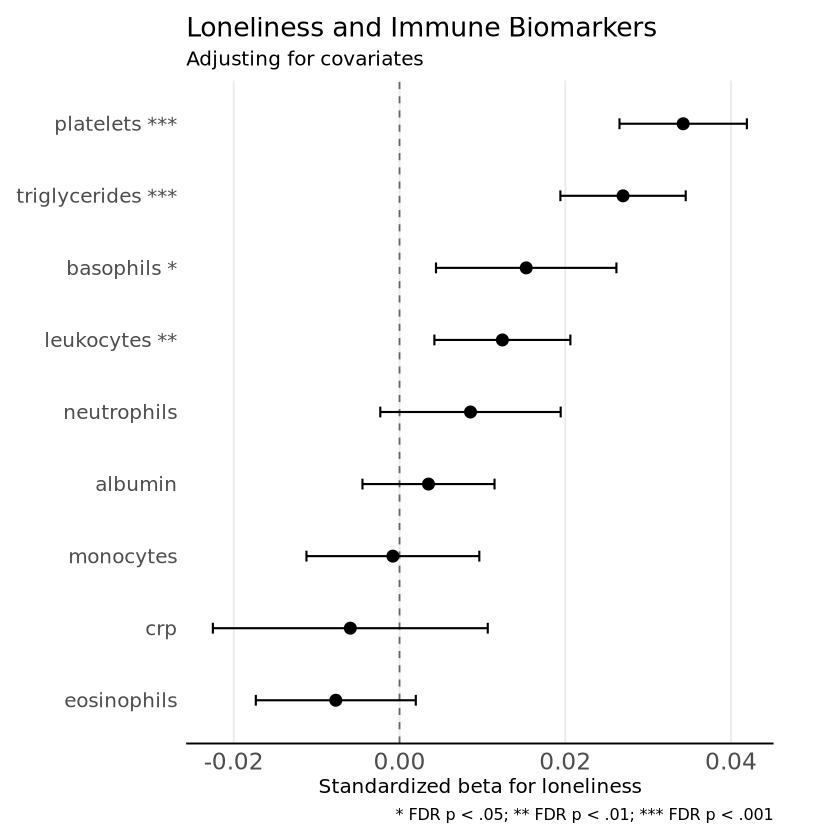

In [112]:
p_biomarker_z <- ggplot(
  biomarker_results,
  aes(
    x = estimate,
    y = reorder(biomarker_label_fdr, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Loneliness and Immune Biomarkers",
    subtitle = "Adjusting for covariates",
    x = "Standardized beta for loneliness",
    y = NULL,
    caption = "* FDR p < .05; ** FDR p < .01; *** FDR p < .001"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.y = element_text(size = 12),
    axis.text.x = element_text(size = 14),
    plot.title = element_text(size = 16, hjust = 0),
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    axis.line.x = element_line(),
    plot.margin = margin(10, 40, 10, 10),
    
  )

p_biomarker_z

In [113]:
# save fig
library(svglite)
ggsave(
  "p_biomarker_z.png",
  plot = p_biomarker_z,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_biomarker_z.svg",
  plot = p_biomarker_z,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


In [114]:
### Fully adjusted associations between loneliness and immune biomarkers

In [116]:
model_biomarkers_joint_raw <- lm(
    total_score ~ basophils_z +
    leukocytes_z +
    platelets_z +
    triglycerides_z +
    age_at_ucla + 
    sex_at_birth +
    race +
    income_c +
    bmi,
    data = dat
)

summary(model_biomarkers_joint_raw)


Call:
lm(formula = total_score ~ basophils_z + leukocytes_z + platelets_z + 
    triglycerides_z + age_at_ucla + sex_at_birth + race + income_c + 
    bmi, data = dat)

Residuals:
     Min       1Q   Median       3Q      Max 
-13.1593  -4.0085  -0.5373   3.6205  18.0258 

Coefficients:
                               Estimate Std. Error t value Pr(>|t|)    
(Intercept)                   10.340191   0.388983  26.583  < 2e-16 ***
basophils_z                    0.037684   0.038225   0.986 0.324210    
leukocytes_z                   0.057383   0.041016   1.399 0.161811    
platelets_z                    0.147394   0.038420   3.836 0.000125 ***
triglycerides_z                0.097706   0.034361   2.844 0.004466 ** 
age_at_ucla                   -0.068168   0.002436 -27.988  < 2e-16 ***
sex_at_birthMale               0.205150   0.073772   2.781 0.005426 ** 
raceAsian                      0.569727   0.400185   1.424 0.154559    
raceBlack or African American -0.483897   0.354761  -1.364 0.172

- adjusting for all other FDR-sig biomarkers, loneliness significantly associated with platelets and triglycerides, mixed race, none of these races, income, bmi, age and se

In [117]:

immune_forest <- tidy(
  model_biomarkers_joint_raw,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(grepl("_z$", term))

In [119]:
immune_forest <- immune_forest %>%
  mutate(
    biomarker = term %>%
      sub("_z$$", "", .) %>%
      recode(
        basophils = "Basophils (z-scored)",
        leukocytes = "Leukocytes (z-scored)",
        platelets = "Platelets (z-scored)",
        triglycerides = "Triglycerides (z-scored)"
      )
  )

`height` was translated to `width`.


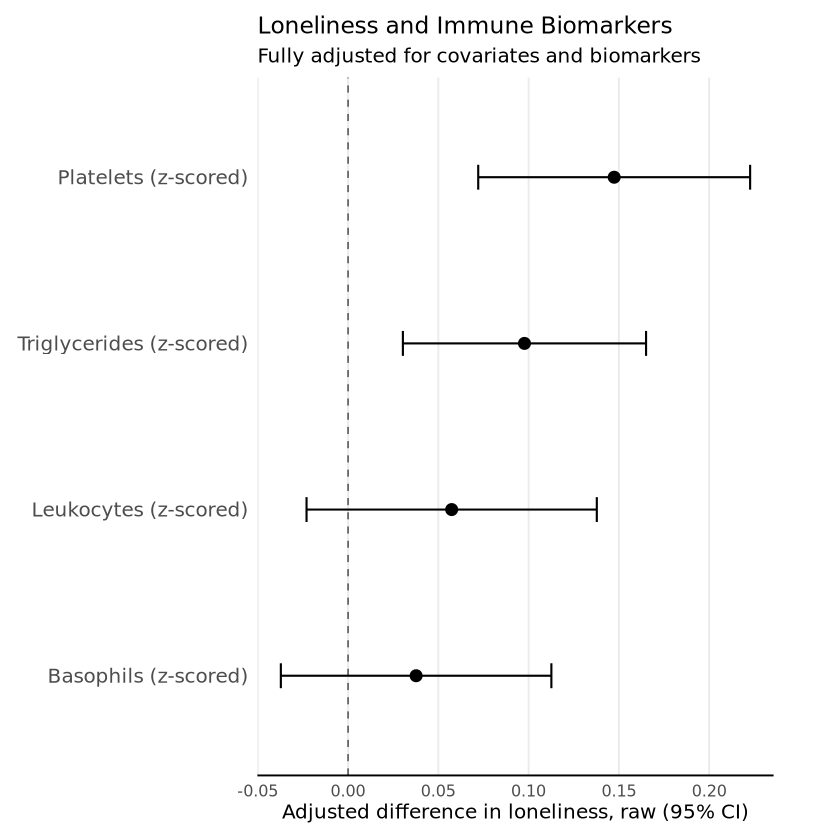

In [120]:
p_immune_joint_raw <- ggplot(
  immune_forest,
  aes(
    x = estimate,
    y = reorder(biomarker, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Loneliness and Immune Biomarkers",
    subtitle = "Fully adjusted for covariates and biomarkers",
    x = "Adjusted difference in loneliness, raw (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    axis.text.y = element_text(size = 12),
    axis.line.x = element_line(),
    plot.title = element_text(
        hjust = 0,
        size = 14),
    plot.margin = margin(
      t = 10,
      r = 40,
      b = 10,
      l = 10
    )
      )
p_immune_joint_raw

In [ ]:
- 1 SD increase in platelets associated with 0.15-point increase in UCLA loneliness scale

In [ ]:
### Z-scored loneliness

In [121]:
model_biomarkers_joint_z <- lm(
    loneliness_z ~ basophils_z +
    leukocytes_z +
    platelets_z +
    triglycerides_z +
    age_at_ucla + 
    sex_at_birth +
    race +
    income_c +
    bmi,
    data = dat
)

summary(model_biomarkers_joint_z)


Call:
lm(formula = loneliness_z ~ basophils_z + leukocytes_z + platelets_z + 
    triglycerides_z + age_at_ucla + sex_at_birth + race + income_c + 
    bmi, data = dat)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.4641 -0.7506 -0.1006  0.6780  3.3754 

Coefficients:
                                Estimate Std. Error t value Pr(>|t|)    
(Intercept)                    0.5182063  0.0728387   7.114 1.16e-12 ***
basophils_z                    0.0070566  0.0071577   0.986 0.324210    
leukocytes_z                   0.0107452  0.0076804   1.399 0.161811    
platelets_z                    0.0276001  0.0071942   3.836 0.000125 ***
triglycerides_z                0.0182959  0.0064342   2.844 0.004466 ** 
age_at_ucla                   -0.0127647  0.0004561 -27.988  < 2e-16 ***
sex_at_birthMale               0.0384153  0.0138141   2.781 0.005426 ** 
raceAsian                      0.1066839  0.0749363   1.424 0.154559    
raceBlack or African American -0.0906118  0.0664305  -1.364 0.17

In [122]:

immune_forest_z <- tidy(
  model_biomarkers_joint_z,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(grepl("_z$", term))

In [123]:
immune_forest_z <- immune_forest_z %>%
  mutate(
    biomarker = term %>%
      sub("_z$$", "", .) %>%
      recode(
        basophils = "Basophils (z-scored)",
        leukocytes = "Leukocytes (z-scored)",
        platelets = "Platelets (z-scored)",
        triglycerides = "Triglycerides (z-scored)"
      )
  )

`height` was translated to `width`.


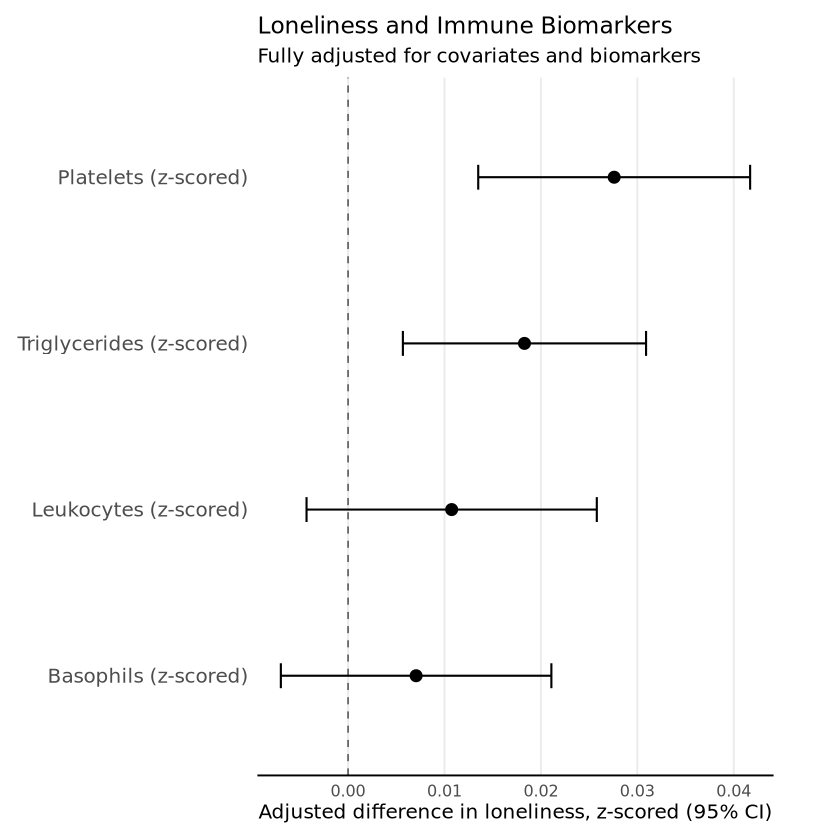

In [124]:
p_immune_joint_z <- ggplot(
  immune_forest_z,
  aes(
    x = estimate,
    y = reorder(biomarker, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Loneliness and Immune Biomarkers",
    subtitle = "Fully adjusted for covariates and biomarkers",
    x = "Adjusted difference in loneliness, z-scored (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    axis.text.y = element_text(size = 12),
    axis.line.x = element_line(),
    plot.title = element_text(
        hjust = 0,
        size = 14),
    plot.margin = margin(
      t = 10,
      r = 40,
      b = 10,
      l = 10
    )
      )
p_immune_joint_z

In [125]:
# save fig
library(svglite)
ggsave(
  "p_immune_joint_z.png",
  plot = p_immune_joint_z,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_immune_joint_z.svg",
  plot = p_immune_joint_z,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


In [ ]:
## Immune Conditions and loneliness

In [129]:
# raw loneliness
immune_conditions <- c("asthma", "allergic_rhinitis", "rheumatoid_arthritis",
                       "hypothyroidism", "ulcerative_colitis", "type2_diabetes",
                       "crohns_disease", "atopic_dermatitis")

immune_logistic_results <- data.frame()

for (dx in immune_conditions) {

  f <- as.formula(
    paste0(
      dx,
      " ~ total_score + age_at_ucla + sex_at_birth + ",
      "race + income_c + bmi"
    )
  )

  model <- glm(
    f,
    data = cohort,
    family = binomial(link = "logit"),
    na.action = na.omit
  )

  s <- summary(model)

  beta <- s$coefficients["total_score", "Estimate"]
  se   <- s$coefficients["total_score", "Std. Error"]
  p    <- s$coefficients["total_score", "Pr(>|z|)"]

  # Model fit indices
  aic <- AIC(model)

  null_dev <- model$null.deviance
  resid_dev <- model$deviance

  # Likelihood-ratio test comparing full model to intercept-only model
  lr_stat <- null_dev - resid_dev
  lr_df <- model$df.null - model$df.residual
  lr_p <- pchisq(
    lr_stat,
    df = lr_df,
    lower.tail = FALSE
 )

  # McFadden pseudo-R2
  mcfadden_r2 <- 1 - (resid_dev / null_dev)

  # Tjur R2
  pred_prob <- fitted(model)

  tjur_r2 <-
    mean(pred_prob[model$y == 1], na.rm = TRUE) -
    mean(pred_prob[model$y == 0], na.rm = TRUE)

  immune_logistic_results <- rbind(
  immune_logistic_results,
  data.frame(
    condition = dx,
    N = nobs(model),
    N_cases = sum(model$y == 1),

    beta_logodds = beta,
    OR = exp(beta),
    CI_lower = exp(beta - 1.96 * se),
    CI_upper = exp(beta + 1.96 * se),
    p_value = p,

    AIC = aic,
    null_deviance = null_dev,
    residual_deviance = resid_dev,

    LR_chisq = lr_stat,
    LR_df = lr_df,
    LR_p = lr_p,

    McFadden_R2 = mcfadden_r2,
    Tjur_R2 = tjur_r2
    )
  )
}

In [130]:
# FDR
immune_logistic_results <- immune_logistic_results %>%
  mutate(
    FDR = p.adjust(p_value, method = "BH"),

    condition_label = recode(
      condition,
      asthma = "Asthma",
      allergic_rhinitis = "Allergic Rhinitis",
      rheumatoid_arthritis = "Rheumatoid Arthritis",
      hypothyroidism = "Hypothyroidism",
      ulcerative_colitis = "Ulcerative Colitis",
      type2_diabetes = "Type 2 Diabetes",
      crohns_disease = "Crohn's Disease",
      atopic_dermatitis = "Atopic Dermatitis"
    ),

    stars = case_when(
      FDR < 0.001 ~ "***",
      FDR < 0.01  ~ "**",
      FDR < 0.05  ~ "*",
      TRUE ~ ""
    ),

    plot_label = ifelse(
      stars == "",
      condition_label,
      paste0(condition_label, " ", stars)
    )
  ) %>%
  arrange(OR)

immune_logistic_results

condition,N,N_cases,beta_logodds,OR,CI_lower,CI_upper,p_value,AIC,null_deviance,residual_deviance,LR_chisq,LR_df,LR_p,McFadden_R2,Tjur_R2,FDR,condition_label,stars,plot_label
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
ulcerative_colitis,183204,1679,0.01121075,1.011274,1.001631,1.021009,2.182145e-02,18968.32,19099.65,18940.32,159.3316,13,2.691567e-27,0.008342121,0.0007543542,2.182145e-02,Ulcerative Colitis,*,Ulcerative Colitis *
crohns_disease,183204,1606,0.01180786,1.011878,1.002094,1.021757,1.722014e-02,18282.89,18412.65,18254.89,157.7614,13,5.592705e-27,0.008568097,0.0007368375,1.968016e-02,Crohn's Disease,*,Crohn's Disease *
atopic_dermatitis,183204,4592,0.01226790,1.012343,1.006514,1.018207,3.132835e-05,42798.70,42922.77,42770.70,152.0640,13,7.908919e-26,0.003542737,0.0008130516,4.177113e-05,Atopic Dermatitis,***,Atopic Dermatitis ***
allergic_rhinitis,183204,34046,0.01238858,1.012466,1.010091,1.014846,4.695826e-25,173701.84,175923.21,173673.84,2249.3746,13,0.000000e+00,0.012786116,0.0117257112,1.252220e-24,Allergic Rhinitis,***,Allergic Rhinitis ***
hypothyroidism,183204,23347,0.01472185,1.014831,1.011972,1.017697,1.468146e-24,130076.15,139779.40,130048.15,9731.2552,13,0.000000e+00,0.069618663,0.0525127866,2.936291e-24,Hypothyroidism,***,Hypothyroidism ***
type2_diabetes,183204,22212,0.01825833,1.018426,1.015499,1.021361,1.681993e-35,118884.74,135348.22,118856.74,16491.4759,13,0.000000e+00,0.121844793,0.0944166237,6.727973e-35,Type 2 Diabetes,***,Type 2 Diabetes ***
asthma,183204,25305,0.02168544,1.021922,1.019255,1.024597,1.850940e-59,143087.48,147129.17,143059.48,4069.6859,13,0.000000e+00,0.027660633,0.0235048106,1.480752e-58,Asthma,***,Asthma ***
rheumatoid_arthritis,183204,4122,0.02575510,1.026090,1.019941,1.032275,4.491861e-17,37943.88,39430.45,37915.88,1514.5677,13,3.130952e-316,0.038411120,0.0083609796,7.186977e-17,Rheumatoid Arthritis,***,Rheumatoid Arthritis ***


`height` was translated to `width`.


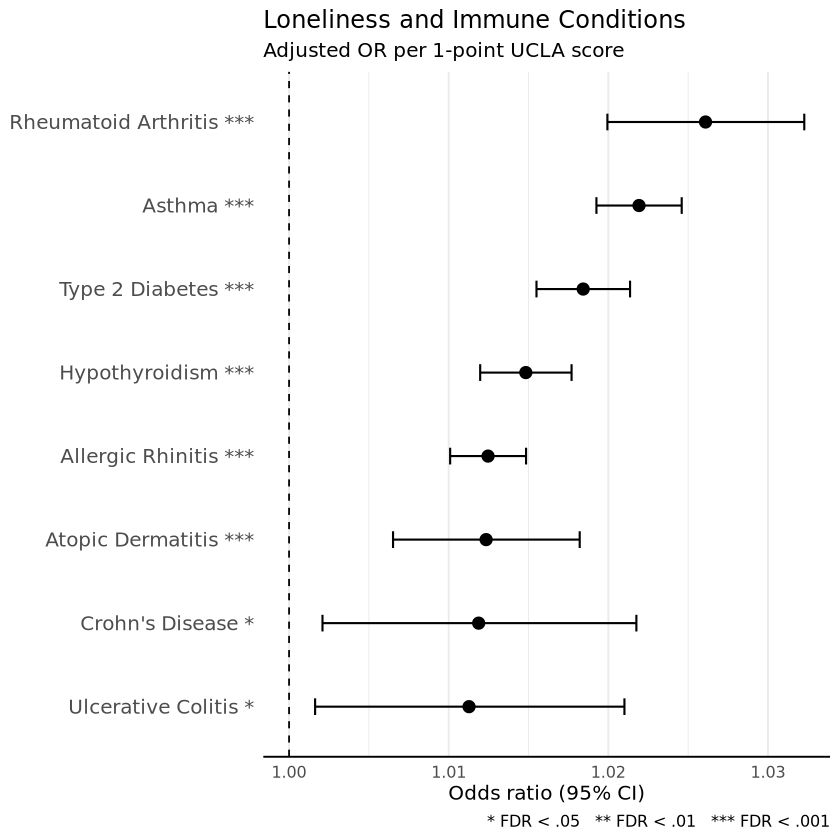

In [131]:
p_immune_or <- ggplot(
  immune_logistic_results,
  aes(
    x = OR,
    y = reorder(plot_label, OR)
  )
) +
  geom_vline(
    xintercept = 1,
    linetype = "dashed",
    linewidth = 0.5
  ) +
  geom_errorbarh(
    aes(
      xmin = CI_lower,
      xmax = CI_upper
    ),
    height = 0.2,
    linewidth = 0.6,
    color = "black"
  ) +
  geom_point(
    size = 3,
    color = "black"
  ) +
  labs(
    title = "Loneliness and Immune Conditions",
    subtitle = "Adjusted OR per 1-point UCLA score",
    x = "Odds ratio (95% CI)",
    y = NULL,
    caption = "* FDR < .05   ** FDR < .01   *** FDR < .001"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    panel.grid.major.y = element_blank(),
    axis.line.x = element_line(),
    axis.text.y = element_text(size = 12)
    
  )

p_immune_or

In [132]:
# save fig
library(svglite)
ggsave(
  "p_immune_or.png",
  plot = p_immune_or,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_immune_or.svg",
  plot = p_immune_or,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


In [35]:
model_immune_conditions_joint_z <- lm(
    loneliness_z ~ 
        asthma +
        allergic_rhinitis +
        rheumatoid_arthritis +
        hypothyroidism +
        ulcerative_colitis +
        type2_diabetes +
        crohns_disease +
        atopic_dermatitis +
        age_at_ucla + 
        sex_at_birth +
        race +
        income_c +
        bmi,
    data = cohort
    )

summary(model_immune_conditions_joint_z)


Call:
lm(formula = loneliness_z ~ asthma + allergic_rhinitis + rheumatoid_arthritis + 
    hypothyroidism + ulcerative_colitis + type2_diabetes + crohns_disease + 
    atopic_dermatitis + age_at_ucla + sex_at_birth + race + income_c + 
    bmi, data = cohort)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.3825 -0.7289 -0.1116  0.6412  3.6762 

Coefficients:
                                Estimate Std. Error  t value Pr(>|t|)    
(Intercept)                    0.2788581  0.0228277   12.216  < 2e-16 ***
asthma                         0.0843116  0.0068481   12.312  < 2e-16 ***
allergic_rhinitis              0.0207513  0.0060664    3.421 0.000625 ***
rheumatoid_arthritis           0.0896081  0.0149566    5.991 2.09e-09 ***
hypothyroidism                 0.0407653  0.0068782    5.927 3.10e-09 ***
ulcerative_colitis             0.0180688  0.0236665    0.763 0.445181    
type2_diabetes                 0.0544093  0.0071696    7.589 3.24e-14 ***
crohns_disease                 0.02467

- loneliness associated with allergic rhinitis, rheumatoid arthritis, hypothyroidism, type 2 diabetes after accounting for comorbidity and covariates

In [135]:
immune_condition_forest_z <- tidy(
  model_immune_conditions_joint_z,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(
    term %in% c(
      "asthma",
      "allergic_rhinitis",
      "rheumatoid_arthritis",
      "hypothyroidism",
      "ulcerative_colitis",
      "type2_diabetes",
      "crohns_disease",
      "atopic_dermatitis"
    )
  )

In [136]:
immune_condition_forest_z <- immune_condition_forest_z %>%
  mutate(
    condition = recode(
      term,
      asthma = "Asthma",
      allergic_rhinitis = "Allergic rhinitis",
      rheumatoid_arthritis = "Rheumatoid arthritis",
      hypothyroidism = "Hypothyroidism",
      ulcerative_colitis = "Ulcerative colitis",
      type2_diabetes = "Type 2 diabetes",
      crohns_disease = "Crohn's disease",
      atopic_dermatitis = "Atopic dermatitis"
    )
  )

`height` was translated to `width`.


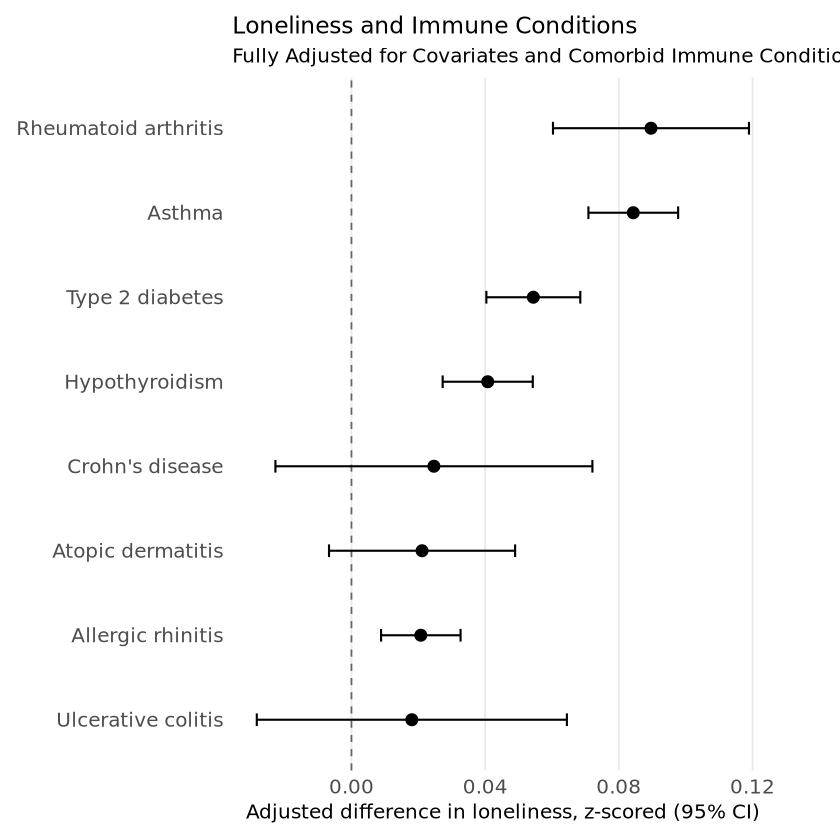

In [140]:
p_immune_conditions <- ggplot(
  immune_condition_forest_z,
  aes(
    x = estimate,
    y = reorder(condition, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Loneliness and Immune Conditions",
    subtitle = "Fully Adjusted for Covariates and Comorbid Immune Conditions",
    x = "Adjusted difference in loneliness, z-scored (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.y = element_text(size = 12),
    axis.text.x = element_text(size = 12),
    plot.title = element_text(size = 14, hjust = 0),
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    plot.margin = margin(10, 40, 10, 10)
  )

p_immune_conditions

In [141]:
# save fig
library(svglite)
ggsave(
  "p_immune_conditions_z.png",
  plot = p_immune_conditions,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_immune_conditions_z.svg",
  plot = p_immune_conditions,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


In [36]:
model_immune_conditions_joint_raw <- lm(
    total_score ~ 
        asthma +
        allergic_rhinitis +
        rheumatoid_arthritis +
        hypothyroidism +
        ulcerative_colitis +
        type2_diabetes +
        crohns_disease +
        atopic_dermatitis +
        age_at_ucla + 
        sex_at_birth +
        race +
        income_c +
        bmi,
    data = cohort
    )

summary(model_immune_conditions_joint_raw)


Call:
lm(formula = total_score ~ asthma + allergic_rhinitis + rheumatoid_arthritis + 
    hypothyroidism + ulcerative_colitis + type2_diabetes + crohns_disease + 
    atopic_dermatitis + age_at_ucla + sex_at_birth + race + income_c + 
    bmi, data = cohort)

Residuals:
     Min       1Q   Median       3Q      Max 
-12.7232  -3.8925  -0.5962   3.4240  19.6319 

Coefficients:
                                Estimate Std. Error  t value Pr(>|t|)    
(Intercept)                    9.0619913  0.1219077   74.335  < 2e-16 ***
asthma                         0.4502519  0.0365709   12.312  < 2e-16 ***
allergic_rhinitis              0.1108188  0.0323965    3.421 0.000625 ***
rheumatoid_arthritis           0.4785371  0.0798733    5.991 2.09e-09 ***
hypothyroidism                 0.2177001  0.0367321    5.927 3.10e-09 ***
ulcerative_colitis             0.0964936  0.1263872    0.763 0.445181    
type2_diabetes                 0.2905640  0.0382882    7.589 3.24e-14 ***
crohns_disease               

In [4]:
# Fully adjusted model (pruning n.s.)

full_family_model_z <- lm(
    loneliness_z ~ 
        anxiety_psych_2plus +
        adhd_psych_2plus +
        asd_psych_2plus + 
        bipolar_psych_2plus +
        eating_disorder_psych_2plus +
        depression_psych_2plus +
        ocd_psych_2plus +
        personality_disorder_psych_2plus +
        ptsd_psych_2plus +
        schizophrenia_psych_2plus +
        asthma +
        allergic_rhinitis +
        rheumatoid_arthritis +
        hypothyroidism +
        ulcerative_colitis +
        type2_diabetes +
        crohns_disease +
        atopic_dermatitis +
        basophils_z +
        leukocytes_z +
        platelets_z +
        triglycerides_z +
        age_at_ucla + 
        sex_at_birth +
        race +
        income_c +
        bmi,
    data = dat
    )

summary(full_family_model_z)


Call:
lm(formula = loneliness_z ~ anxiety_psych_2plus + adhd_psych_2plus + 
    asd_psych_2plus + bipolar_psych_2plus + eating_disorder_psych_2plus + 
    depression_psych_2plus + ocd_psych_2plus + personality_disorder_psych_2plus + 
    ptsd_psych_2plus + schizophrenia_psych_2plus + asthma + allergic_rhinitis + 
    rheumatoid_arthritis + hypothyroidism + ulcerative_colitis + 
    type2_diabetes + crohns_disease + atopic_dermatitis + basophils_z + 
    leukocytes_z + platelets_z + triglycerides_z + age_at_ucla + 
    sex_at_birth + race + income_c + bmi, data = dat)

Residuals:
     Min       1Q   Median       3Q      Max 
-3.11245 -0.71004 -0.08909  0.63859  3.15301 

Coefficients:
                                   Estimate Std. Error t value Pr(>|t|)    
(Intercept)                       0.1811243  0.0714769   2.534 0.011283 *  
anxiety_psych_2plus               0.1062527  0.0161872   6.564 5.35e-11 ***
adhd_psych_2plus                  0.0793111  0.0258957   3.063 0.002196 ** 
as

- anxiety, adhd, asd, bipolar, depression, personality disorder, ptsd, asthma, allergic rhinitis, platelets, age, sex, asian race, mixed race, none of these races, white race, income and bmi remain associated in the full model

In [8]:
full_joint_forest_z <- tidy(
  full_family_model_z,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(
    term %in% c(
      "asthma",
      "allergic_rhinitis",
      "rheumatoid_arthritis",
      "hypothyroidism",
      "ulcerative_colitis",
      "type2_diabetes",
      "crohns_disease",
      "atopic_dermatitis",
      "basophils_z",
      "leukocytes_z",
      "platelets_z",
      "triglycerides_z",
      "anxiety_psych_2plus",
      "adhd_psych_2plus",
      "asd_psych_2plus", 
      "bipolar_psych_2plus" ,
      "eating_disorder_psych_2plus",
      "depression_psych_2plus", 
      "ocd_psych_2plus",
      "personality_disorder_psych_2plus",
      "ptsd_psych_2plus",
      "schizophrenia_psych_2plus"  
    )
  )

full_joint_forest_z <- full_joint_forest_z %>%
  mutate(
    term = recode(
      term,
      asthma = "Asthma",
      allergic_rhinitis = "Allergic rhinitis",
      rheumatoid_arthritis = "Rheumatoid arthritis",
      hypothyroidism = "Hypothyroidism",
      ulcerative_colitis = "Ulcerative colitis",
      type2_diabetes = "Type 2 diabetes",
      crohns_disease = "Crohn's disease",
      atopic_dermatitis = "Atopic dermatitis",
      
    )
  )

full_joint_forest_z <- full_joint_forest_z %>%
  mutate(
    term = term %>%
      sub("_z$$", "", .) %>%
      recode(
        basophils = "Basophils (z-scored)",
        leukocytes = "Leukocytes (z-scored)",
        platelets = "Platelets (z-scored)",
        triglycerides = "Triglycerides (z-scored)"
      )
  )

full_joint_forest_z <- full_joint_forest_z %>%
  mutate(
    term = term %>%
      sub("_psych_2plus$", "", .) %>%
      recode(
        anxiety = "Anxiety",
        depression = "Depression",
        ptsd = "PTSD",
        adhd = "ADHD",
        asd = "Autism spectrum disorder",
        bipolar = "Bipolar disorder",
        eating_disorder = "Eating disorder",
        ocd = "OCD",
        personality_disorder = "Personality disorder",
        schizophrenia = "Schizophrenia"
      )
  )

In [12]:
full_joint_forest_z <- full_joint_forest_z %>%
  mutate(
    stars = case_when(
      p.value < 0.001 ~ "***",
      p.value < 0.01  ~ "**",
      p.value < 0.05  ~ "*",
      TRUE ~ ""
    ),
    plot_label = ifelse(
      stars == "",
      term,
      paste0(term, " ", stars)
    )
  )

`height` was translated to `width`.


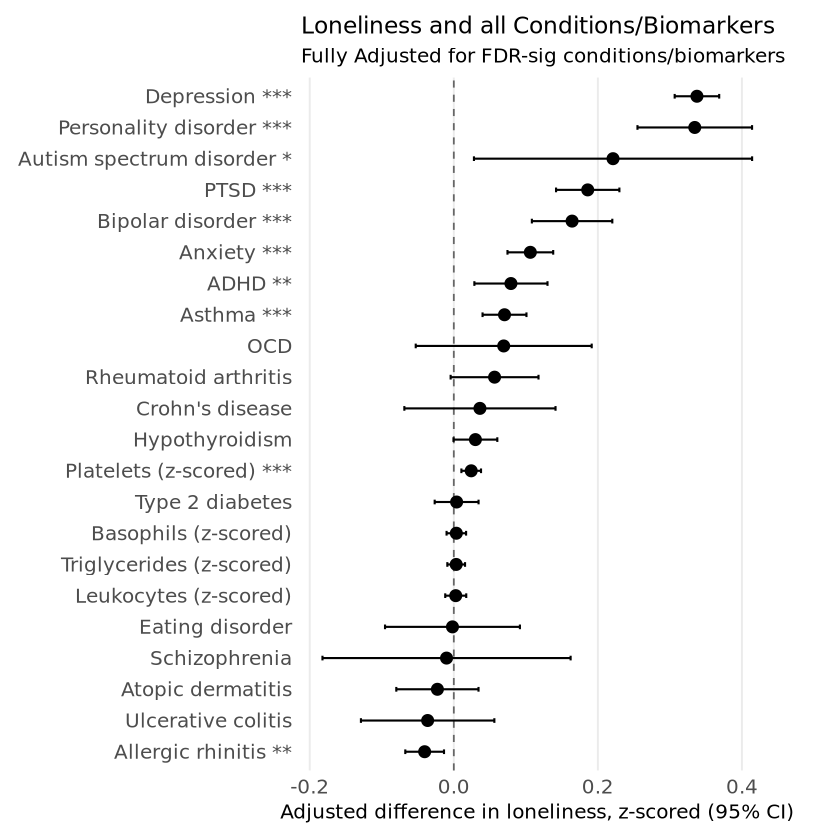

In [14]:
p_full_joint <- ggplot(
  full_joint_forest_z,
  aes(
    x = estimate,
    y = reorder(plot_label, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Loneliness and all Conditions/Biomarkers",
    subtitle = "Fully Adjusted for FDR-sig conditions/biomarkers",
    x = "Adjusted difference in loneliness, z-scored (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.y = element_text(size = 12),
    axis.text.x = element_text(size = 12),
    plot.title = element_text(size = 14, hjust = 0),
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    plot.margin = margin(10, 40, 10, 10)
  )

p_full_joint

In [16]:
# save fig
library(svglite)
ggsave(
  "p_full_joint_z.png",
  plot = p_full_joint,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_full_joint_z.svg",
  plot = p_full_joint,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.


- strongest association with loneliness is depression (1.8 ish raw increase in UCLA loneliness scale), 0.4 SD increase
- platelets only remaining immune biomarker

In [15]:
full_family_model_raw <- lm(
    total_score ~ 
        anxiety_psych_2plus +
        adhd_psych_2plus +
        asd_psych_2plus + 
        bipolar_psych_2plus +
        eating_disorder_psych_2plus +
        depression_psych_2plus +
        ocd_psych_2plus +
        personality_disorder_psych_2plus +
        ptsd_psych_2plus +
        schizophrenia_psych_2plus +
        asthma +
        allergic_rhinitis +
        rheumatoid_arthritis +
        hypothyroidism +
        ulcerative_colitis +
        type2_diabetes +
        crohns_disease +
        atopic_dermatitis +
        basophils_z +
        leukocytes_z +
        platelets_z +
        triglycerides_z +
        age_at_ucla + 
        sex_at_birth +
        race +
        income_c +
        bmi,
    data = dat
    )

summary(full_family_model_raw)


Call:
lm(formula = total_score ~ anxiety_psych_2plus + adhd_psych_2plus + 
    asd_psych_2plus + bipolar_psych_2plus + eating_disorder_psych_2plus + 
    depression_psych_2plus + ocd_psych_2plus + personality_disorder_psych_2plus + 
    ptsd_psych_2plus + schizophrenia_psych_2plus + asthma + allergic_rhinitis + 
    rheumatoid_arthritis + hypothyroidism + ulcerative_colitis + 
    type2_diabetes + crohns_disease + atopic_dermatitis + basophils_z + 
    leukocytes_z + platelets_z + triglycerides_z + age_at_ucla + 
    sex_at_birth + race + income_c + bmi, data = dat)

Residuals:
     Min       1Q   Median       3Q      Max 
-16.6215  -3.7919  -0.4757   3.4103  16.8381 

Coefficients:
                                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)                       8.540060   0.381710  22.373  < 2e-16 ***
anxiety_psych_2plus               0.567425   0.086445   6.564 5.35e-11 ***
adhd_psych_2plus                  0.423548   0.138292   3.063 0.002196 ** 
asd_psy

In [17]:
### Replicating with 1 Diagnosis
full_family_model_1plus_z <- lm(
    loneliness_z ~ 
        anxiety_psych_1plus +
        adhd_psych_1plus +
        asd_psych_1plus + 
        bipolar_psych_1plus +
        eating_disorder_psych_1plus +
        depression_psych_1plus +
        ocd_psych_1plus +
        personality_disorder_psych_1plus +
        ptsd_psych_1plus +
        schizophrenia_psych_1plus +
        asthma +
        allergic_rhinitis +
        rheumatoid_arthritis +
        hypothyroidism +
        ulcerative_colitis +
        type2_diabetes +
        crohns_disease +
        atopic_dermatitis +
        basophils_z +
        leukocytes_z +
        platelets_z +
        triglycerides_z +
        age_at_ucla + 
        sex_at_birth +
        race +
        income_c +
        bmi,
    data = dat
    )

summary(full_family_model_1plus_z)


Call:
lm(formula = loneliness_z ~ anxiety_psych_1plus + adhd_psych_1plus + 
    asd_psych_1plus + bipolar_psych_1plus + eating_disorder_psych_1plus + 
    depression_psych_1plus + ocd_psych_1plus + personality_disorder_psych_1plus + 
    ptsd_psych_1plus + schizophrenia_psych_1plus + asthma + allergic_rhinitis + 
    rheumatoid_arthritis + hypothyroidism + ulcerative_colitis + 
    type2_diabetes + crohns_disease + atopic_dermatitis + basophils_z + 
    leukocytes_z + platelets_z + triglycerides_z + age_at_ucla + 
    sex_at_birth + race + income_c + bmi, data = dat)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.1173 -0.7089 -0.0876  0.6399  3.1796 

Coefficients:
                                   Estimate Std. Error t value Pr(>|t|)    
(Intercept)                       0.0926259  0.0715380   1.295 0.195409    
anxiety_psych_1plus               0.1069189  0.0156471   6.833 8.52e-12 ***
adhd_psych_1plus                  0.1006592  0.0231461   4.349 1.37e-05 ***
asd_psych_1p

In [18]:
full_joint_forest_1plus_z <- tidy(
  full_family_model_1plus_z,
  conf.int = TRUE,
  conf.level = 0.95
) %>%
  filter(
    term %in% c(
      "asthma",
      "allergic_rhinitis",
      "rheumatoid_arthritis",
      "hypothyroidism",
      "ulcerative_colitis",
      "type2_diabetes",
      "crohns_disease",
      "atopic_dermatitis",
      "basophils_z",
      "leukocytes_z",
      "platelets_z",
      "triglycerides_z",
      "anxiety_psych_1plus",
      "adhd_psych_1plus",
      "asd_psych_1plus", 
      "bipolar_psych_1plus" ,
      "eating_disorder_psych_1plus",
      "depression_psych_1plus", 
      "ocd_psych_1plus",
      "personality_disorder_psych_1plus",
      "ptsd_psych_1plus",
      "schizophrenia_psych_1plus"  
    )
  )

full_joint_forest_1plus_z <- full_joint_forest_1plus_z %>%
  mutate(
    term = recode(
      term,
      asthma = "Asthma",
      allergic_rhinitis = "Allergic rhinitis",
      rheumatoid_arthritis = "Rheumatoid arthritis",
      hypothyroidism = "Hypothyroidism",
      ulcerative_colitis = "Ulcerative colitis",
      type2_diabetes = "Type 2 diabetes",
      crohns_disease = "Crohn's disease",
      atopic_dermatitis = "Atopic dermatitis",
      
    )
  )

full_joint_forest_1plus_z <- full_joint_forest_1plus_z %>%
  mutate(
    term = term %>%
      sub("_z$$", "", .) %>%
      recode(
        basophils = "Basophils (z-scored)",
        leukocytes = "Leukocytes (z-scored)",
        platelets = "Platelets (z-scored)",
        triglycerides = "Triglycerides (z-scored)"
      )
  )

full_joint_forest_1plus_z <- full_joint_forest_1plus_z %>%
  mutate(
    term = term %>%
      sub("_psych_1plus$", "", .) %>%
      recode(
        anxiety = "Anxiety",
        depression = "Depression",
        ptsd = "PTSD",
        adhd = "ADHD",
        asd = "Autism spectrum disorder",
        bipolar = "Bipolar disorder",
        eating_disorder = "Eating disorder",
        ocd = "OCD",
        personality_disorder = "Personality disorder",
        schizophrenia = "Schizophrenia"
      )
  )

full_joint_forest_1plus_z <- full_joint_forest_1plus_z %>%
  mutate(
    stars = case_when(
      p.value < 0.001 ~ "***",
      p.value < 0.01  ~ "**",
      p.value < 0.05  ~ "*",
      TRUE ~ ""
    ),
    plot_label = ifelse(
      stars == "",
      term,
      paste0(term, " ", stars)
    )
  )

`height` was translated to `width`.


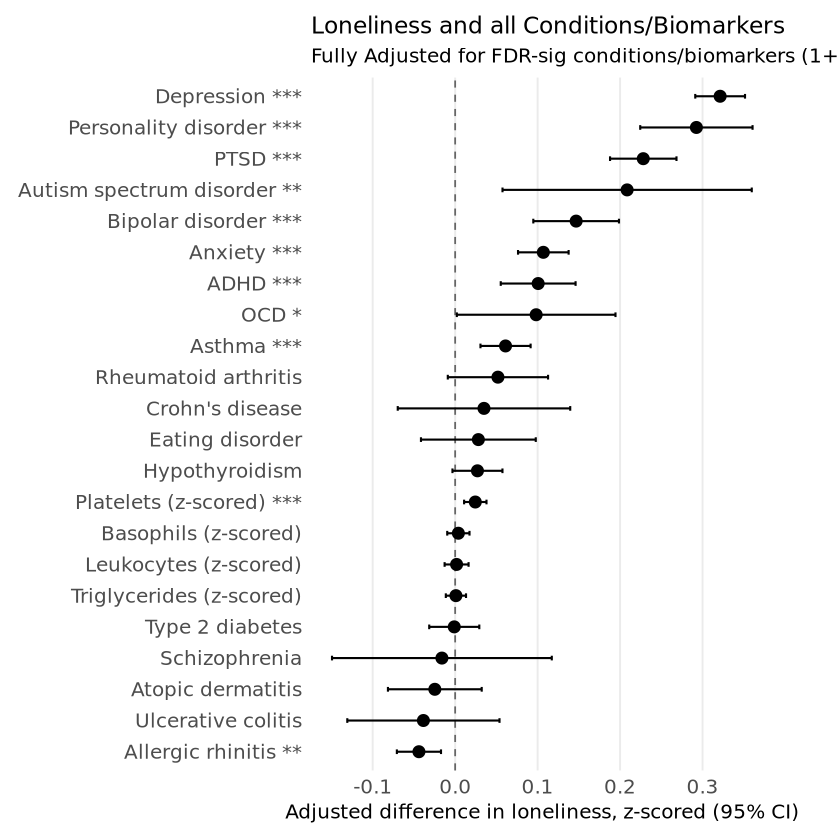

In [19]:
p_full_joint_1plus <- ggplot(
  full_joint_forest_1plus_z,
  aes(
    x = estimate,
    y = reorder(plot_label, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = conf.low,
      xmax = conf.high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Loneliness and all Conditions/Biomarkers",
    subtitle = "Fully Adjusted for FDR-sig conditions/biomarkers (1+ Diagnosis Instance for Psych)",
    x = "Adjusted difference in loneliness, z-scored (95% CI)",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.y = element_text(size = 12),
    axis.text.x = element_text(size = 12),
    plot.title = element_text(size = 14, hjust = 0),
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank(),
    plot.margin = margin(10, 40, 10, 10)
  )

p_full_joint_1plus

In [26]:
binary_vars <- c(
  # Immune conditions
  "asthma",
  "allergic_rhinitis",
  "rheumatoid_arthritis",
  "hypothyroidism",
  "ulcerative_colitis",
  "type2_diabetes",
  "crohns_disease",
  "atopic_dermatitis",

  # Psychiatric diagnoses (2+ diagnosis dates)
  "anxiety_psych_1plus",
  "depression_psych_1plus",
  "ptsd_psych_1plus",
  "adhd_psych_1plus",
  "asd_psych_1plus",
  "bipolar_psych_1plus",
  "eating_disorder_psych_1plus",
  "ocd_psych_1plus",
  "personality_disorder_psych_1plus",
  "schizophrenia_psych_1plus"
)

In [28]:
analysis_dat <- model.frame(full_family_model_1plus_z)

sample_size_table <- tibble(
  variable = binary_vars,
  N_total = nrow(analysis_dat),
  N_cases = sapply(
    binary_vars,
    function(v) sum(analysis_dat[[v]] == 1, na.rm = TRUE)
  ),
  N_noncases = sapply(
    binary_vars,
    function(v) sum(analysis_dat[[v]] == 0, na.rm = TRUE)
  )
) %>%
  mutate(
    prevalence_pct = 100 * N_cases / N_total
  )

sample_size_table

variable,N_total,N_cases,N_noncases,prevalence_pct
<chr>,<int>,<int>,<int>,<dbl>
asthma,22761,5178,17583,22.7494398
allergic_rhinitis,22761,7654,15107,33.6276965
rheumatoid_arthritis,22761,947,21814,4.1606256
hypothyroidism,22761,4913,17848,21.5851676
ulcerative_colitis,22761,418,22343,1.8364747
type2_diabetes,22761,5698,17063,25.0340495
crohns_disease,22761,324,22437,1.4234875
atopic_dermatitis,22761,1092,21669,4.7976802
anxiety_psych_1plus,22761,11350,11411,49.8659989


In [48]:
### Exporting Linear Model Results

library(broom)
library(dplyr)
library(purrr)

export_lm_results <- function(model, model_name) {

  N_model <- nrow(model.frame(model))
  outcome_name <- all.vars(formula(model))[1]

  coef_tab <- broom::tidy(
    model,
    conf.int = TRUE,
    conf.level = 0.95
  ) %>%
    mutate(
      model_name = model_name,
      model_type = "linear",
      outcome = outcome_name,
      N = N_model
    ) %>%
    select(
      model_name,
      model_type,
      outcome,
      N,
      term,
      estimate,
      std.error,
      conf.low,
      conf.high,
      statistic,
      p.value
    )

  fit_tab <- broom::glance(model) %>%
    mutate(
      model_name = model_name,
      model_type = "linear",
      outcome = outcome_name,
      N = N_model
    )

  list(
    coefficients = coef_tab,
    fit = fit_tab
  )
}

In [49]:
### Exporting Logistic Model Results

export_glm_results <- function(model, model_name) {

  N_model <- nrow(model.frame(model))
  outcome_name <- all.vars(formula(model))[1]

  coef_tab <- broom::tidy(
    model,
    conf.int = TRUE,
    conf.level = 0.95
  ) %>%
    mutate(
      model_name = model_name,
      model_type = "logistic",
      outcome = outcome_name,
      N = N_model,
      OR = exp(estimate),
      OR_low = exp(conf.low),
      OR_high = exp(conf.high)
    ) %>%
    select(
      model_name,
      model_type,
      outcome,
      N,
      term,
      estimate,
      std.error,
      conf.low,
      conf.high,
      OR,
      OR_low,
      OR_high,
      statistic,
      p.value
    )

  fit_tab <- broom::glance(model) %>%
    mutate(
      model_name = model_name,
      model_type = "logistic",
      outcome = outcome_name,
      N = N_model
    )

  list(
    coefficients = coef_tab,
    fit = fit_tab
  )
}

In [45]:
class(full_family_model_raw)

[1] "lm"

In [50]:
### Run on fitted models

psych_joint_out_z <- export_lm_results(
  model_psych_joint_z,
  "Psychiatric conditions joint model (z-scored)"
)

psych_joint_out_raw <- export_lm_results(
  model_psych_joint_raw,
  "Psychiatric conditions joint model (raw)"
)

immune_joint_out_z <- export_lm_results(
  model_immune_conditions_joint_z,
  "Immune conditions joint model (z-scored)"
)

immune_joint_out_raw <- export_lm_results(
  model_immune_conditions_joint_raw,
  "Immune conditions joint model (raw)"
)

full_joint_out_z <- export_lm_results(
  full_family_model_z,
  "Psychiatric + immune conditions joint model (z-scored)"
)

full_joint_out_raw <- export_lm_results(
  full_family_model_raw,
  "Psychiatric + immune conditions joint model (raw)"
)

In [52]:
psych_joint_out_z$coefficients
psych_joint_out_z$fit

model_name,model_type,outcome,N,term,estimate,std.error,conf.low,conf.high,statistic,p.value
<chr>,<chr>,<chr>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,(Intercept),0.212414077,0.0224237940,0.168463958,0.256364196,9.4727091,2.757575e-21
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,anxiety_psych_2plus,0.035932520,0.0067664450,0.022670444,0.049194596,5.3103987,1.095128e-07
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,adhd_psych_2plus,0.042786436,0.0118527406,0.019555338,0.066017534,3.6098348,3.064737e-04
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,asd_psych_2plus,0.341912113,0.0435750728,0.256505975,0.427318250,7.8465070,4.300750e-15
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,bipolar_psych_2plus,0.175698975,0.0144748885,0.147328527,0.204069422,12.1381920,6.829341e-34
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,eating_disorder_psych_2plus,0.017578929,0.0221228342,-0.025781316,0.060939173,0.7946056,4.268440e-01
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,depression_psych_2plus,0.300042259,0.0068328322,0.286650065,0.313434453,43.9118434,0.000000e+00
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,ocd_psych_2plus,0.051719128,0.0301759371,-0.007425013,0.110863269,1.7139195,8.654520e-02
Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204,personality_disorder_psych_2plus,0.283442500,0.0232541086,0.237864984,0.329020017,12.1889213,3.671366e-34


r.squared,adj.r.squared,sigma,statistic,p.value,df,logLik,AIC,BIC,deviance,df.residual,nobs,model_name,model_type,outcome,N
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<chr>,<chr>,<chr>,<int>
0.1445639,0.1444612,0.9247149,1407.116,0,22,-245604.4,491256.8,491499.6,156637.6,183181,183204,Psychiatric conditions joint model (z-scored),linear,loneliness_z,183204


In [53]:
# giant table
all_coefficients <- bind_rows(
  psych_joint_out_z$coefficients,
  psych_joint_out_raw$coefficients,
  immune_joint_out_z$coefficients,
  immune_joint_out_raw$coefficients,
  full_joint_out_z$coefficients,
  full_joint_out_raw$coefficients
)

all_model_fit <- bind_rows(
  psych_joint_out_z$fit,
  psych_joint_out_raw$fit,
  immune_joint_out_z$fit,
  immune_joint_out_raw$fit,
  full_joint_out_z$fit,
  full_joint_out_raw$fit
)

In [54]:
all_coefficients <- all_coefficients %>%
  mutate(
    estimate_ci = sprintf(
      "%.3f [%.3f, %.3f]",
      estimate,
      conf.low,
      conf.high
    ),
    p_display = case_when(
      p.value < 0.001 ~ "<0.001",
      TRUE ~ sprintf("%.3f", p.value)
    )
  )

In [55]:
write.csv(
  all_coefficients,
  "regression_coefficients_all_models.csv",
  row.names = FALSE
)

write.csv(
  all_model_fit,
  "regression_model_fit_all_models.csv",
  row.names = FALSE
)

saveRDS(
  all_coefficients,
  "regression_coefficients_all_models.rds"
)

saveRDS(
  all_model_fit,
  "regression_model_fit_all_models.rds"
)

In [56]:
system(
  'gcloud storage cp regression_coefficients_all_models.csv "$WORKSPACE_BUCKET/workspace/conference_results"'
)

system(
  'gcloud storage cp regression_model_fit_all_models.csv "$WORKSPACE_BUCKET/workspace/conference_results"'
)

system(
  'gcloud storage cp regression_coefficients_all_models.rds "$WORKSPACE_BUCKET/workspace/conference_results"'
)

system(
  'gcloud storage cp regression_model_fit_all_models.rds "$WORKSPACE_BUCKET/workspace/conference_results"'
)

### Mediation Models
1) see if association between loneliness -> depression mediated by platelets
2) see if association between loneliness -> platelets mediated by depression
3) see if depression -> platelets -> loneliness
4) see if platelets -> loneliness -> depression

In [132]:
## Mediation Model 1
# loneliness -> platelets -> depression

# loneliness -> platelets
m_platelets <- lm(
  platelets_z ~ loneliness_z +
    age_at_ucla +
    sex_at_birth +
    race +
    income_c +
    bmi,
  data = dat
)

# outcome model
# platelets + loneliness -> depression
y_depression <- glm(
  depression_psych_2plus ~
    loneliness_z +
    platelets_z +
    age_at_ucla +
    sex_at_birth +
    race +
    income_c +
    bmi,
  family = binomial(),
  data = dat
)

### Loneliness -> Platelets -> Depression ?

In [133]:
med_dat <- dat %>%
  select(
    loneliness_z,
    platelets_z,
    depression_psych_2plus,
    age_at_ucla,
    sex_at_birth,
    race,
    income_c,
    bmi
  ) %>%
  na.omit()

In [134]:
m_model <- lm(
  platelets_z ~ loneliness_z +
    age_at_ucla +
    sex_at_birth +
    race +
    income_c +
    bmi,
  data = med_dat
)

y_model <- glm(
  depression_psych_2plus ~
    loneliness_z +
    platelets_z +
    age_at_ucla +
    sex_at_birth +
    race +
    income_c +
    bmi,
  family = binomial(),
  data = med_dat
)

In [60]:
summary(m_model)
summary(y_model)


Call:
lm(formula = platelets_z ~ loneliness_z + age_at_ucla + sex_at_birth + 
    race + income_c + bmi, data = med_dat)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.7296 -0.5980 -0.0832  0.4990 15.1700 

Coefficients:
                                Estimate Std. Error t value Pr(>|t|)    
(Intercept)                    0.4369811  0.0406838  10.741  < 2e-16 ***
loneliness_z                   0.0342238  0.0039209   8.729  < 2e-16 ***
age_at_ucla                   -0.0104364  0.0002508 -41.609  < 2e-16 ***
sex_at_birthMale              -0.4689560  0.0079351 -59.099  < 2e-16 ***
raceAsian                      0.0394715  0.0422790   0.934    0.351    
raceBlack or African American  0.0559084  0.0380863   1.468    0.142    
raceI prefer not to answer    -0.0273801  0.0998745  -0.274    0.784    
raceMore than one population   0.0253453  0.0390947   0.648    0.517    
raceNone Indicated             0.0032727  0.0388429   0.084    0.933    
raceNone of these             -0.030592


Call:
glm(formula = depression_psych_2plus ~ loneliness_z + platelets_z + 
    age_at_ucla + sex_at_birth + race + income_c + bmi, family = binomial(), 
    data = med_dat)

Coefficients:
                                Estimate Std. Error z value Pr(>|z|)    
(Intercept)                   -1.0684068  0.0956084 -11.175  < 2e-16 ***
loneliness_z                   0.4724461  0.0092615  51.012  < 2e-16 ***
platelets_z                    0.0327554  0.0093169   3.516 0.000439 ***
age_at_ucla                   -0.0062066  0.0005949 -10.434  < 2e-16 ***
sex_at_birthMale              -0.3282146  0.0195400 -16.797  < 2e-16 ***
raceAsian                     -0.6403946  0.1049514  -6.102 1.05e-09 ***
raceBlack or African American -0.2677466  0.0896794  -2.986 0.002830 ** 
raceI prefer not to answer     0.0441256  0.2322500   0.190 0.849316    
raceMore than one population   0.0389333  0.0917421   0.424 0.671291    
raceNone Indicated            -0.1496705  0.0915735  -1.634 0.102168    
raceNone

### Monte-Carlo Simulation of Confidence Intervals for Indirect Effect
- AoU not compiling with mediation packages 

In [135]:
library(dplyr)
library(tibble)

# a path: loneliness -> platelets
a_est <- coef(summary(m_model))["loneliness_z", "Estimate"]
a_se  <- coef(summary(m_model))["loneliness_z", "Std. Error"]

a_ci_low  <- a_est - 1.96 * a_se
a_ci_high <- a_est + 1.96 * a_se


# b path: platelets -> depression, accounting for loneliness
b_est <- coef(summary(y_model))["platelets_z", "Estimate"]
b_se  <- coef(summary(y_model))["platelets_z", "Std. Error"]

b_ci_low  <- b_est - 1.96 * b_se
b_ci_high <- b_est + 1.96 * b_se


# c' path: loneliness -> depression, accounting for platelets
c_est <- coef(summary(y_model))["loneliness_z", "Estimate"]
c_se  <- coef(summary(y_model))["loneliness_z", "Std. Error"]

c_ci_low  <- c_est - 1.96 * c_se
c_ci_high <- c_est + 1.96 * c_se

# p-values
a_p <- coef(summary(m_model))["loneliness_z", "Pr(>|t|)"]

b_p <- coef(summary(y_model))["platelets_z", "Pr(>|z|)"]

c_p <- coef(summary(y_model))["loneliness_z", "Pr(>|z|)"]

In [136]:
mediation_paths <- tibble(
  pathway = c(
    "Loneliness → Platelets",
    "Platelets → Depression | Loneliness",
    "Loneliness → Depression | Platelets"
  ),

  effect_type = c(
    "Standardized beta",
    "Odds ratio",
    "Odds ratio"
  ),

  estimate = c(
    a_est,
    exp(b_est),
    exp(c_est)
  ),

  ci_low = c(
    a_ci_low,
    exp(b_ci_low),
    exp(c_ci_low)
  ),

  ci_high = c(
    a_ci_high,
    exp(b_ci_high),
    exp(c_ci_high)
  ),

  p_value = c(
    a_p,
    b_p,
    c_p
  )
)

mediation_paths

pathway,effect_type,estimate,ci_low,ci_high,p_value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Loneliness → Platelets,Standardized beta,0.0342238,0.0265388,0.0419088,2.641711e-18
Platelets → Depression | Loneliness,Odds ratio,1.0332978,1.0145999,1.0523402,4.385831e-04
Loneliness → Depression | Platelets,Odds ratio,1.6039127,1.5750602,1.6332938,0.000000e+00


- 1 SD increase in loneliness increases the OR of depression by 60%!
- 1 SD increase in platelet count increases the OR of depression by 3.33%

In [137]:
mediation_paths_display <- mediation_paths %>%
  mutate(
    effect_95CI = sprintf(
      "%.3f [%.3f, %.3f]",
      estimate,
      ci_low,
      ci_high
    ),
    p_display = case_when(
      p_value < 0.001 ~ "<0.001",
      TRUE ~ sprintf("%.3f", p_value)
    )
  ) %>%
  select(
    pathway,
    effect_type,
    effect_95CI,
    p_display
  )

mediation_paths_display

pathway,effect_type,effect_95CI,p_display
<chr>,<chr>,<chr>,<chr>
Loneliness → Platelets,Standardized beta,"0.034 [0.027, 0.042]",<0.001
Platelets → Depression | Loneliness,Odds ratio,"1.033 [1.015, 1.052]",<0.001
Loneliness → Depression | Platelets,Odds ratio,"1.604 [1.575, 1.633]",<0.001


In [138]:
### monte-carlo CI simulation
set.seed(123)

nsim <- 10000

a_sim <- rnorm(
  nsim,
  mean = a_est,
  sd = a_se
)

b_sim <- rnorm(
  nsim,
  mean = b_est,
  sd = b_se
)

indirect_sim <- a_sim * b_sim

In [139]:
# estimating indirect effect using mc
indirect_est <- a_est * b_est

indirect_ci <- quantile(
  indirect_sim,
  probs = c(0.025, 0.975),
  na.rm = TRUE
)

indirect_results <- tibble(
  pathway = "Loneliness → Platelets → Depression",
  effect_type = "Monte Carlo indirect effect",
  estimate = indirect_est,
  ci_low = unname(indirect_ci[1]),
  ci_high = unname(indirect_ci[2])
)

p_mc <- 2 * min(
  mean(indirect_sim <= 0),
  mean(indirect_sim >= 0)
)

indirect_results <- indirect_results %>%
  mutate(
    p_value = p_mc
  )

indirect_results

pathway,effect_type,estimate,ci_low,ci_high,p_value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Loneliness → Platelets → Depression,Monte Carlo indirect effect,0.001121015,0.0004804357,0.001825941,0


In [140]:
indirect_results_display <- indirect_results %>%
  mutate(
    effect_95CI = sprintf(
      "%.4f [%.4f, %.4f]",
      estimate,
      ci_low,
      ci_high
    ),
    p_display = case_when(
      p_value < 0.001 ~ "<0.001",
      TRUE ~ sprintf("%.3f", p_value)
    )
  ) %>%
  select(
    pathway,
    effect_type,
    effect_95CI,
    p_display
  )

indirect_results_display 

pathway,effect_type,effect_95CI,p_display
<chr>,<chr>,<chr>,<chr>
Loneliness → Platelets → Depression,Monte Carlo indirect effect,"0.0011 [0.0005, 0.0018]",<0.001


### Loneliness --> Depression --> Platelets?

In [106]:
table(
  med_dat$depression_psych_2plus,
  useNA = "ifany"
)


    0     1 
40350 22911 

In [141]:
m_model_2 <- glm(
  depression_psych_2plus ~ loneliness_z +
    age_at_ucla +
    sex_at_birth +
    race +
    income_c +
    bmi,
    family = "binomial",
  data = med_dat
)

y_model_2 <- lm(
  platelets_z ~
    loneliness_z +
    depression_psych_2plus +
    age_at_ucla +
    sex_at_birth +
    race +
    income_c +
    bmi,
  data = med_dat
)

In [96]:
summary(m_model_2)
summary(y_model_2)


Call:
glm(formula = depression_psych_2plus ~ loneliness_z + age_at_ucla + 
    sex_at_birth + race + income_c + bmi, family = "binomial", 
    data = med_dat)

Coefficients:
                                Estimate Std. Error z value Pr(>|z|)    
(Intercept)                   -1.0540910  0.0954898 -11.039  < 2e-16 ***
loneliness_z                   0.4735245  0.0092566  51.155  < 2e-16 ***
age_at_ucla                   -0.0065502  0.0005867 -11.164  < 2e-16 ***
sex_at_birthMale              -0.3435615  0.0190486 -18.036  < 2e-16 ***
raceAsian                     -0.6388817  0.1049277  -6.089 1.14e-09 ***
raceBlack or African American -0.2658599  0.0896544  -2.965  0.00302 ** 
raceI prefer not to answer     0.0430173  0.2323311   0.185  0.85311    
raceMore than one population   0.0397510  0.0917194   0.433  0.66473    
raceNone Indicated            -0.1495884  0.0915499  -1.634  0.10227    
raceNone of these              0.1631467  0.1213151   1.345  0.17868    
racePMI: Skip         


Call:
lm(formula = platelets_z ~ loneliness_z + depression_psych_2plus + 
    age_at_ucla + sex_at_birth + race + income_c + bmi, data = med_dat)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.7110 -0.5974 -0.0827  0.4987 15.1758 

Coefficients:
                                Estimate Std. Error t value Pr(>|t|)    
(Intercept)                    0.4290708  0.0407391  10.532  < 2e-16 ***
loneliness_z                   0.0311787  0.0040106   7.774 7.71e-15 ***
depression_psych_2plus         0.0296070  0.0082157   3.604 0.000314 ***
age_at_ucla                   -0.0103955  0.0002511 -41.407  < 2e-16 ***
sex_at_birthMale              -0.4668956  0.0079549 -58.693  < 2e-16 ***
raceAsian                      0.0427710  0.0422849   1.011 0.311783    
raceBlack or African American  0.0576076  0.0380856   1.513 0.130391    
raceI prefer not to answer    -0.0276986  0.0998650  -0.277 0.781504    
raceMore than one population   0.0251077  0.0390910   0.642 0.520689    
raceNone Indic

In [142]:
library(dplyr)
library(tibble)

# a path: loneliness -> depression
a_est_2 <- coef(summary(m_model_2))["loneliness_z", "Estimate"]
a_se_2  <- coef(summary(m_model_2))["loneliness_z", "Std. Error"]

a_ci_low_2  <- a_est_2 - 1.96 * a_se_2
a_ci_high_2 <- a_est_2 + 1.96 * a_se_2


# b path: depression -> platelets, accounting for loneliness
b_est_2 <- coef(summary(y_model_2))["depression_psych_2plus", "Estimate"]
b_se_2 <- coef(summary(y_model_2))["depression_psych_2plus", "Std. Error"]

b_ci_low_2  <- b_est_2 - 1.96 * b_se_2
b_ci_high_2 <- b_est_2 + 1.96 * b_se_2


# c' path: loneliness -> platelets, accounting for depression
c_est_2 <- coef(summary(y_model_2))["loneliness_z", "Estimate"]
c_se_2  <- coef(summary(y_model_2))["loneliness_z", "Std. Error"]

c_ci_low_2  <- c_est_2 - 1.96 * c_se_2
c_ci_high_2 <- c_est_2 + 1.96 * c_se_2

# p-values
a_p_2 <- coef(summary(m_model_2))["loneliness_z", "Pr(>|z|)"]

b_p_2 <- coef(summary(y_model_2))["depression_psych_2plus", "Pr(>|t|)"]

c_p_2 <- coef(summary(y_model_2))["loneliness_z", "Pr(>|t|)"]

In [143]:
mediation_paths_2 <- tibble(
  pathway = c(
    "Loneliness → Depression",
    "Depression → Platelets | Loneliness",
    "Loneliness → Platelets | Depression"
  ),

  effect_type = c(
    "OR",
    "Standardized beta",
    "Standardized beta"
  ),

  estimate = c(
    exp(a_est_2),
    b_est_2,
    c_est_2
  ),

  ci_low = c(
    exp(a_ci_low_2),
    b_ci_low_2,
    c_ci_low_2
  ),

  ci_high = c(
    exp(a_ci_high_2),
    b_ci_high_2,
    c_ci_high_2
  ),

  p_value = c(
    a_p_2,
    b_p_2,
    c_p_2
  )
)

mediation_paths_2

pathway,effect_type,estimate,ci_low,ci_high,p_value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Loneliness → Depression,OR,1.60564336,1.57677493,1.63504033,0.000000e+00
Depression → Platelets | Loneliness,Standardized beta,0.02960698,0.01350421,0.04570975,3.139494e-04
Loneliness → Platelets | Depression,Standardized beta,0.03117866,0.02331794,0.03903939,7.711790e-15


In [144]:
mediation_paths_display_2 <- mediation_paths_2 %>%
  mutate(
    effect_95CI = sprintf(
      "%.3f [%.3f, %.3f]",
      estimate,
      ci_low,
      ci_high
    ),
    p_display = case_when(
      p_value < 0.001 ~ "<0.001",
      TRUE ~ sprintf("%.3f", p_value)
    )
  ) %>%
  select(
    pathway,
    effect_type,
    effect_95CI,
    p_display
  )

mediation_paths_display_2

pathway,effect_type,effect_95CI,p_display
<chr>,<chr>,<chr>,<chr>
Loneliness → Depression,OR,"1.606 [1.577, 1.635]",<0.001
Depression → Platelets | Loneliness,Standardized beta,"0.030 [0.014, 0.046]",<0.001
Loneliness → Platelets | Depression,Standardized beta,"0.031 [0.023, 0.039]",<0.001


In [145]:
set.seed(123)

nsim <- 10000

a_sim_2 <- rnorm(
  nsim,
  mean = a_est_2,
  sd = a_se_2
)

b_sim_2 <- rnorm(
  nsim,
  mean = b_est_2,
  sd = b_se_2
)

indirect_sim_2 <- a_sim_2 * b_sim_2

In [146]:
indirect_est_2 <- a_est_2 * b_est_2

indirect_ci_2 <- quantile(
  indirect_sim_2,
  probs = c(0.025, 0.975),
  na.rm = TRUE
)

indirect_results_2 <- tibble(
  pathway = "Loneliness → Depression → Platelets",
  effect_type = "Monte Carlo indirect effect",
  estimate = indirect_est_2,
  ci_low = unname(indirect_ci_2[1]),
  ci_high = unname(indirect_ci_2[2])
)

p_mc_2 <- 2 * min(
  mean(indirect_sim_2 <= 0),
  mean(indirect_sim_2 >= 0)
)

indirect_results_2 <- indirect_results_2 %>%
  mutate(
    p_value = p_mc_2
  )

indirect_results_2

pathway,effect_type,estimate,ci_low,ci_high,p_value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Loneliness → Depression → Platelets,Monte Carlo indirect effect,0.01401963,0.006414183,0.02166727,0


- indirect effect of loneliness -> depression -> platelets is stronger than loneliness -> platelets -> depression
- 0.014 vs 0.0011

### Depression -> Platelets -> Loneliness?

In [147]:
m_model_3 <- lm(
  platelets_z ~ depression_psych_2plus +
    age_at_ucla +
    sex_at_birth +
    race +
    income_c +
    bmi,
  data = med_dat
)

y_model_3 <- lm(
  loneliness_z ~
    platelets_z +
    depression_psych_2plus +
    age_at_ucla +
    sex_at_birth +
    race +
    income_c +
    bmi,
  data = med_dat
)

In [148]:
# a path: depression -> loneliness
a_est_3 <- coef(summary(m_model_3))["depression_psych_2plus", "Estimate"]
a_se_3  <- coef(summary(m_model_3))["depression_psych_2plus", "Std. Error"]

a_ci_low_3  <- a_est_3 - 1.96 * a_se_3
a_ci_high_3 <- a_est_3 + 1.96 * a_se_3


# b path: platelets -> loneliness, accounting for depression
b_est_3 <- coef(summary(y_model_3))["platelets_z", "Estimate"]
b_se_3 <- coef(summary(y_model_3))["platelets_z", "Std. Error"]

b_ci_low_3  <- b_est_3 - 1.96 * b_se_3
b_ci_high_3 <- b_est_3 + 1.96 * b_se_3


# c' path: depression -> loneliness, accounting for platlets
c_est_3 <- coef(summary(y_model_3))["depression_psych_2plus", "Estimate"]
c_se_3  <- coef(summary(y_model_3))["depression_psych_2plus", "Std. Error"]

c_ci_low_3  <- c_est_3 - 1.96 * c_se_3
c_ci_high_3 <- c_est_3 + 1.96 * c_se_3

# p-values
a_p_3 <- coef(summary(m_model_3))["depression_psych_2plus", "Pr(>|t|)"]

b_p_3 <- coef(summary(y_model_3))["platelets_z", "Pr(>|t|)"]

c_p_3 <- coef(summary(y_model_3))["depression_psych_2plus", "Pr(>|t|)"]

In [149]:
mediation_paths_3 <- tibble(
  pathway = c(
    "Depression → Loneliness",
    "Platelets → Loneliness | Depression",
    "Depression → Loneliness | Platelets"
  ),

  effect_type = c(
    "Standardized beta",
    "Standardized beta",
    "Standardized beta"
  ),

  estimate = c(
    a_est_3,
    b_est_3,
    c_est_3
  ),

  ci_low = c(
    a_ci_low_3,
    b_ci_low_3,
    c_ci_low_3
  ),

  ci_high = c(
    a_ci_high_3,
    b_ci_high_3,
    c_ci_high_3
  ),

  p_value = c(
    a_p_3,
    b_p_3,
    c_p_3
  )
)

mediation_paths_3

pathway,effect_type,estimate,ci_low,ci_high,p_value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Depression → Loneliness,Standardized beta,0.04306392,0.02731522,0.05881261,8.373913e-08
Platelets → Loneliness | Depression,Standardized beta,0.03061939,0.02289966,0.03833911,7.711790e-15
Depression → Loneliness | Platelets,Standardized beta,0.43028855,0.41468553,0.44589157,0.000000e+00


In [ ]:
- depression diagnosis (vs none) increases loneliness by 0.43 SD accounting for platelets

In [150]:
nsim <- 10000

a_sim_3 <- rnorm(
  nsim,
  mean = a_est_3,
  sd = a_se_3
)

b_sim_3 <- rnorm(
  nsim,
  mean = b_est_3,
  sd = b_se_3
)

indirect_sim_3 <- a_sim_3 * b_sim_3

In [151]:
indirect_est_3 <- a_est_3 * b_est_3

indirect_ci_3 <- quantile(
  indirect_sim_3,
  probs = c(0.025, 0.975),
  na.rm = TRUE
)

indirect_results_3 <- tibble(
  pathway = "Depression → Platelets → Loneliness",
  effect_type = "Monte Carlo indirect effect",
  estimate = indirect_est_3,
  ci_low = unname(indirect_ci_3[1]),
  ci_high = unname(indirect_ci_3[2])
)

p_mc_3 <- 2 * min(
  mean(indirect_sim_3 <= 0),
  mean(indirect_sim_3 >= 0)
)

indirect_results_3 <- indirect_results_3 %>%
  mutate(
    p_value = p_mc_3
  )

indirect_results_3

pathway,effect_type,estimate,ci_low,ci_high,p_value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Depression → Platelets → Loneliness,Monte Carlo indirect effect,0.001318591,0.0007808634,0.001939142,0


In [ ]:
- small indirect effect (b = 0.001)
- loneliness -> depression -> platelets has stronger evidence still 

### Depression -> Loneliness -> Platelets
- an immune response associted with loneliness and depression?

In [152]:
m_model_4 <- lm(
  loneliness_z ~ depression_psych_2plus +
    age_at_ucla +
    sex_at_birth +
    race +
    income_c +
    bmi,
  data = med_dat
)

y_model_4 <- lm(
  platelets_z ~
    loneliness_z +
    depression_psych_2plus +
    age_at_ucla +
    sex_at_birth +
    race +
    income_c +
    bmi,
  data = med_dat
)

In [153]:
# a path: depression -> platelets
a_est_4 <- coef(summary(m_model_4))["depression_psych_2plus", "Estimate"]
a_se_4  <- coef(summary(m_model_4))["depression_psych_2plus", "Std. Error"]

a_ci_low_4  <- a_est_4 - 1.96 * a_se_4
a_ci_high_4 <- a_est_4 + 1.96 * a_se_4


# b path: loneliness -> platelets, accounting for depression
b_est_4 <- coef(summary(y_model_4))["loneliness_z", "Estimate"]
b_se_4 <- coef(summary(y_model_4))["loneliness_z", "Std. Error"]

b_ci_low_4 <- b_est_4 - 1.96 * b_se_4
b_ci_high_4 <- b_est_4 + 1.96 * b_se_4


# c' path: depression -> paltelets, accounting for loneliness
c_est_4 <- coef(summary(y_model_4))["depression_psych_2plus", "Estimate"]
c_se_4  <- coef(summary(y_model_4))["depression_psych_2plus", "Std. Error"]

c_ci_low_4  <- c_est_4 - 1.96 * c_se_4
c_ci_high_4 <- c_est_4 + 1.96 * c_se_4

# p-values
a_p_4 <- coef(summary(m_model_4))["depression_psych_2plus", "Pr(>|t|)"]

b_p_4 <- coef(summary(y_model_4))["loneliness_z", "Pr(>|t|)"]

c_p_4 <- coef(summary(y_model_4))["depression_psych_2plus", "Pr(>|t|)"]

In [154]:
mediation_paths_4 <- tibble(
  pathway = c(
    "Depression → Platelets",
    "Loneliness → Platelets | Depression",
    "Depression → Platelets | Loneliness"
  ),

  effect_type = c(
    "Standardized beta",
    "Standardized beta",
    "Standardized beta"
  ),

  estimate = c(
    a_est_4,
    b_est_4,
    c_est_4
  ),

  ci_low = c(
    a_ci_low_4,
    b_ci_low_4,
    c_ci_low_4
  ),

  ci_high = c(
    a_ci_high_4,
    b_ci_high_4,
    c_ci_high_4
  ),

  p_value = c(
    a_p_4,
    b_p_4,
    c_p_4
  )
)

mediation_paths_4

pathway,effect_type,estimate,ci_low,ci_high,p_value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Depression → Platelets,Standardized beta,0.43160714,0.41600034,0.44721394,0.000000e+00
Loneliness → Platelets | Depression,Standardized beta,0.03117866,0.02331794,0.03903939,7.711790e-15
Depression → Platelets | Loneliness,Standardized beta,0.02960698,0.01350421,0.04570975,3.139494e-04


In [155]:
nsim <- 10000

a_sim_4 <- rnorm(
  nsim,
  mean = a_est_4,
  sd = a_se_4
)

b_sim_4 <- rnorm(
  nsim,
  mean = b_est_4,
  sd = b_se_4
)

indirect_sim_4 <- a_sim_4 * b_sim_4

In [156]:
indirect_est_4 <- a_est_4 * b_est_4

indirect_ci_4 <- quantile(
  indirect_sim_4,
  probs = c(0.025, 0.975),
  na.rm = TRUE
)

indirect_results_4 <- tibble(
  pathway = "Depression → Loneliness → Platelets",
  effect_type = "Monte Carlo indirect effect",
  estimate = indirect_est_4,
  ci_low = unname(indirect_ci_4[1]),
  ci_high = unname(indirect_ci_4[2])
)

p_mc_4 <- 2 * min(
  mean(indirect_sim_4 <= 0),
  mean(indirect_sim_4 >= 0)
)

indirect_results_4 <- indirect_results_4 %>%
  mutate(
    p_value = p_mc_4
  )

indirect_results_4

pathway,effect_type,estimate,ci_low,ci_high,p_value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Depression → Loneliness → Platelets,Monte Carlo indirect effect,0.01345693,0.01004268,0.01698839,0


In [ ]:
- indirect effect of depression -> loneliness -> platelets (b=0.013), similar to loneliness -> depression -> platelets (b = 0.014)

In [ ]:
### Platelets --> Loneliness --> Depression?

In [157]:
m_model_5 <- lm(
  loneliness_z ~ platelets_z +
    age_at_ucla +
    sex_at_birth +
    race +
    income_c +
    bmi,
  data = med_dat
)

y_model_5 <- glm(
  depression_psych_2plus ~
    loneliness_z +
    platelets_z +
    age_at_ucla +
    sex_at_birth +
    race +
    income_c +
    bmi,
    family = "binomial",
  data = med_dat
)

In [158]:
# a path: platelets -> loneliness
a_est_5 <- coef(summary(m_model_5))["platelets_z", "Estimate"]
a_se_5  <- coef(summary(m_model_5))["platelets_z", "Std. Error"]

a_ci_low_5  <- a_est_5 - 1.96 * a_se_5
a_ci_high_5 <- a_est_5 + 1.96 * a_se_5


# b path: Loneliness -> Depression, accounting for platelets
b_est_5 <- coef(summary(y_model_5))["loneliness_z", "Estimate"]
b_se_5 <- coef(summary(y_model_5))["loneliness_z", "Std. Error"]

b_ci_low_5 <- b_est_5 - 1.96 * b_se_5
b_ci_high_5 <- b_est_5 + 1.96 * b_se_5


# c' path: plateletes -> depression, accounting for loneliness
c_est_5 <- coef(summary(y_model_5))["platelets_z", "Estimate"]
c_se_5  <- coef(summary(y_model_5))["platelets_z", "Std. Error"]

c_ci_low_5  <- c_est_5 - 1.96 * c_se_5
c_ci_high_5 <- c_est_5 + 1.96 * c_se_5

# p-values
a_p_5 <- coef(summary(m_model_5))["platelets_z", "Pr(>|t|)"]

b_p_5 <- coef(summary(y_model_5))["loneliness_z", "Pr(>|z|)"]

c_p_5 <- coef(summary(y_model_5))["platelets_z", "Pr(>|z|)"]

In [159]:
mediation_paths_5 <- tibble(
  pathway = c(
    "Platelets → Loneliness",
    "Loneliness → Depression | Platelets",
    "Platelets → Depression | Loneliness"
  ),

  effect_type = c(
    "Standardized beta",
    "OR",
    "OR"
  ),

  estimate = c(
   a_est_5,
   exp(b_est_5),
   exp(c_est_5)
  ),

  ci_low = c(
    a_ci_low_5,
   exp(b_ci_low_5),
    exp(c_ci_low_5)
  ),

  ci_high = c(
    a_ci_high_5,
    exp(b_ci_high_5),
    exp(c_ci_high_5)
  ),

  p_value = c(
    a_p_5,
    b_p_5,
    c_p_5
  )
)

mediation_paths_5

pathway,effect_type,estimate,ci_low,ci_high,p_value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Platelets → Loneliness,Standardized beta,0.03515524,0.02726109,0.0430494,2.641711e-18
Loneliness → Depression | Platelets,OR,1.60391270,1.57506015,1.6332938,0.000000e+00
Platelets → Depression | Loneliness,OR,1.03329777,1.01459989,1.0523402,4.385831e-04


In [160]:
nsim <- 10000

a_sim_5 <- rnorm(
  nsim,
  mean = a_est_5,
  sd = a_se_5
)

b_sim_5 <- rnorm(
  nsim,
  mean = b_est_5,
  sd = b_se_5
)

indirect_sim_5 <- a_sim_5 * b_sim_5

In [161]:
indirect_est_5 <- a_est_5 * b_est_5

indirect_ci_5 <- quantile(
  indirect_sim_5,
  probs = c(0.025, 0.975),
  na.rm = TRUE
)

indirect_results_5 <- tibble(
  pathway = "Plateletes → Loneliness → Depression",
  effect_type = "Monte Carlo indirect effect",
  estimate = indirect_est_5,
  ci_low = unname(indirect_ci_5[1]),
  ci_high = unname(indirect_ci_5[2])
)

p_mc_5 <- 2 * min(
  mean(indirect_sim_5 <= 0),
  mean(indirect_sim_5 >= 0)
)

indirect_results_5 <- indirect_results_5 %>%
  mutate(
    p_value = p_mc_5
  )

indirect_results_5

pathway,effect_type,estimate,ci_low,ci_high,p_value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Plateletes → Loneliness → Depression,Monte Carlo indirect effect,0.01660896,0.01281678,0.02028154,0


In [ ]:
- indirect effect 0.017 which is the largest effect?


In [171]:
# MODEL 6: Platelets → Depression → Loneliness

m_model_6 <- glm(
  depression_psych_2plus ~ platelets_z +
    age_at_ucla +
    sex_at_birth +
    race +
    income_c +
    bmi,
  family = binomial,
  data = med_dat
)

y_model_6 <- lm(
  loneliness_z ~
    platelets_z +
    depression_psych_2plus +
    age_at_ucla +
    sex_at_birth +
    race +
    income_c +
    bmi,
  data = med_dat
)


# a path: Platelets -> Depression
# Logistic model, so report as OR
a_est_6 <- coef(summary(m_model_6))["platelets_z", "Estimate"]
a_se_6  <- coef(summary(m_model_6))["platelets_z", "Std. Error"]

a_ci_low_6  <- a_est_6 - 1.96 * a_se_6
a_ci_high_6 <- a_est_6 + 1.96 * a_se_6


# b path: Depression -> Loneliness, accounting for Platelets
# Linear model, so standardized beta
b_est_6 <- coef(summary(y_model_6))[
  "depression_psych_2plus",
  "Estimate"
]

b_se_6 <- coef(summary(y_model_6))[
  "depression_psych_2plus",
  "Std. Error"
]

b_ci_low_6  <- b_est_6 - 1.96 * b_se_6
b_ci_high_6 <- b_est_6 + 1.96 * b_se_6


# c' path: Platelets -> Loneliness, accounting for Depression
# Linear model, so standardized beta
c_est_6 <- coef(summary(y_model_6))[
  "platelets_z",
  "Estimate"
]

c_se_6 <- coef(summary(y_model_6))[
  "platelets_z",
  "Std. Error"
]

c_ci_low_6  <- c_est_6 - 1.96 * c_se_6
c_ci_high_6 <- c_est_6 + 1.96 * c_se_6


# p-values
a_p_6 <- coef(summary(m_model_6))[
  "platelets_z",
  "Pr(>|z|)"
]

b_p_6 <- coef(summary(y_model_6))[
  "depression_psych_2plus",
  "Pr(>|t|)"
]

c_p_6 <- coef(summary(y_model_6))[
  "platelets_z",
  "Pr(>|t|)"
]


# Component-path table
mediation_paths_6 <- tibble(
  pathway = c(
    "Platelets → Depression",
    "Depression → Loneliness | Platelets",
    "Platelets → Loneliness | Depression"
  ),

  effect_type = c(
    "OR",
    "Standardized beta",
    "Standardized beta"
  ),

  estimate = c(
    exp(a_est_6),
    b_est_6,
    c_est_6
  ),

  ci_low = c(
    exp(a_ci_low_6),
    b_ci_low_6,
    c_ci_low_6
  ),

  ci_high = c(
    exp(a_ci_high_6),
    b_ci_high_6,
    c_ci_high_6
  ),

  p_value = c(
    a_p_6,
    b_p_6,
    c_p_6
  )
)

mediation_paths_6

pathway,effect_type,estimate,ci_low,ci_high,p_value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Platelets → Depression,OR,1.04959598,1.03105987,1.06846533,1.011608e-07
Depression → Loneliness | Platelets,Standardized beta,0.43028855,0.41468553,0.44589157,0.000000e+00
Platelets → Loneliness | Depression,Standardized beta,0.03061939,0.02289966,0.03833911,7.711790e-15


In [173]:
set.seed(123)

nsim <- 1000

a_sim_6 <- rnorm(
  nsim,
  mean = a_est_6,
  sd = a_se_6
)

b_sim_6 <- rnorm(
  nsim,
  mean = b_est_6,
  sd = b_se_6
)

indirect_sim_6 <- a_sim_6 * b_sim_6

indirect_est_6 <- a_est_6 * b_est_6

indirect_ci_6 <- quantile(
  indirect_sim_6,
  probs = c(0.025, 0.975),
  na.rm = TRUE
)

p_mc_6 <- 2 * min(
  mean(indirect_sim_6 <= 0),
  mean(indirect_sim_6 >= 0)
)

indirect_results_6 <- tibble(
  pathway = "Platelets → Depression → Loneliness",
  effect_type = "Monte Carlo indirect effect",
  estimate = indirect_est_6,
  ci_low = unname(indirect_ci_6[1]),
  ci_high = unname(indirect_ci_6[2]),
  p_value = p_mc_6
)

indirect_results_6

pathway,effect_type,estimate,ci_low,ci_high,p_value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Platelets → Depression → Loneliness,Monte Carlo indirect effect,0.02082825,0.01325692,0.02901895,0


In [ ]:
### Summary
indirect_results
indirect_results
indirect_results

In [174]:
all_indirect_results <- bind_rows(
  indirect_results   %>% mutate(model = "Model 1"),
  indirect_results_2 %>% mutate(model = "Model 2"),
  indirect_results_3 %>% mutate(model = "Model 3"),
  indirect_results_4 %>% mutate(model = "Model 4"),
  indirect_results_5 %>% mutate(model = "Model 5"),
  indirect_results_6 %>% mutate(model = "Model 6"),
)

In [175]:
all_indirect_results <- bind_rows(
  indirect_results %>%
    mutate(model = "Loneliness → Platelets → Depression"),

  indirect_results_2 %>%
    mutate(model = "Loneliness → Depression → Platelets"),

  indirect_results_3 %>%
    mutate(model = "Depression → Platelets → Loneliness"),

  indirect_results_4 %>%
    mutate(model = "Depression → Loneliness → Platelets"),

  indirect_results_5 %>%
    mutate(model = "Platelets → Loneliness → Depression"),

  indirect_results_6 %>%
    mutate(model = "Platelets → Depression → Loneliness")
)

In [176]:
all_indirect_results %>%
  select(
    model,
    estimate,
    ci_low,
    ci_high,
    everything()
  )

model,estimate,ci_low,ci_high,pathway,effect_type,p_value
<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>
Loneliness → Platelets → Depression,0.001121015,0.0004804357,0.001825941,Loneliness → Platelets → Depression,Monte Carlo indirect effect,0
Loneliness → Depression → Platelets,0.014019632,0.0064141826,0.021667268,Loneliness → Depression → Platelets,Monte Carlo indirect effect,0
Depression → Platelets → Loneliness,0.001318591,0.0007808634,0.001939142,Depression → Platelets → Loneliness,Monte Carlo indirect effect,0
Depression → Loneliness → Platelets,0.013456934,0.0100426834,0.016988387,Depression → Loneliness → Platelets,Monte Carlo indirect effect,0
Platelets → Loneliness → Depression,0.016608957,0.0128167753,0.020281543,Plateletes → Loneliness → Depression,Monte Carlo indirect effect,0
Platelets → Depression → Loneliness,0.020828251,0.0132569228,0.029018948,Platelets → Depression → Loneliness,Monte Carlo indirect effect,0


In [179]:
p_mediation_forest <- ggplot(
  all_indirect_results,
  aes(
    x = estimate,
    y = reorder(model, estimate)
  )
) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    linewidth = 0.5,
    color = "grey40"
  ) +
  geom_errorbarh(
    aes(
      xmin = ci_low,
      xmax = ci_high
    ),
    height = 0.15,
    linewidth = 0.6
  ) +
  geom_point(
    size = 3,
    shape = 21,
    fill = "black",
    color = "black",
    stroke = 0.5
  ) +
  labs(
    title = "Indirect effects across mediation models",
    x = "Monte Carlo indirect effect",
    y = NULL
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.y = element_text(size = 13),
    panel.grid.major.y = element_blank(),
    panel.grid.minor = element_blank()
  )

In [180]:
# save fig
library(svglite)
ggsave(
  "p_mediation_forest.png",
  plot = p_mediation_forest,
  width = 8,
  height = 8,
  dpi = 300
)

ggsave(
  "p_mediation_forest.svg",
  plot = p_mediation_forest,
  width = 8,
  height = 8
)

`height` was translated to `width`.
`height` was translated to `width`.
